<center><h1>Huang_Shane_HW4</h1></center>
<br>
<br>

Name: Shane Huang
<br>
Github Username: shae513351
<br>
USC ID: 5886395143

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

import numpy as np
import pandas as pd

Get the AReM Data Set

In [2]:
# checking a dataset to find the ideal structure(shape,time...)
DATA_DIR = Path("../data/AReM")

COLUMNS = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

file_path = DATA_DIR/"bending1"/"dataset1.csv"

df = pd.read_csv(
    file_path,
    comment="#", #ignore metadata started with #
    header=None
)

df.columns = COLUMNS

print(df.head())
print(df.tail())

df.shape
df.columns
df.info()
df.isna().sum()

   time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0     0      39.25       0.43      22.75       0.43      33.75        1.3
1   250      39.25       0.43      23.00       0.00      33.00        0.0
2   500      39.25       0.43      23.25       0.43      33.00        0.0
3   750      39.50       0.50      23.00       0.71      33.00        0.0
4  1000      39.50       0.50      24.00       0.00      33.00        0.0
       time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
475  118750      43.33       0.47      25.00       0.00       30.0        0.0
476  119000      43.50       0.50      25.50       0.50       30.0        0.0
477  119250      43.50       0.50      24.75       0.43       30.0        0.0
478  119500      43.50       0.50      24.33       0.47       30.0        0.0
479  119750      43.50       0.50      24.25       0.43       30.0        0.0
<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 7 colum

time         0
avg_rss12    0
var_rss12    0
avg_rss13    0
var_rss13    0
avg_rss23    0
var_rss23    0
dtype: int64

In [3]:
#inspecting all files

all_files = sorted(DATA_DIR.glob("*/*.csv"))

inspection_results = []
read_errors = []

for file_path in all_files:
    
    relative_path = str(file_path.relative_to(DATA_DIR))
    
    try:
        current_df = pd.read_csv(
            file_path,
            comment="#",
            header=None
        )
        
        inspection_results.append({
            "file": relative_path,
            "rows": current_df.shape[0],
            "columns": current_df.shape[1],
            "missing_values": current_df.isna().sum().sum(),
        })
        
    except Exception as error:
        read_errors.append({
            "file": relative_path,
            "error_type": type(error).__name__,
            "error_message": str(error)
        })

inspection_df = pd.DataFrame(inspection_results)
#inspection_df

unusual_files = inspection_df[
    (inspection_df["rows"] != 480)
    | (inspection_df["columns"] != 7)
    | (inspection_df["missing_values"] > 0)
]

display(unusual_files)

error_df = pd.DataFrame(read_errors)

display(error_df)

,file,rows,columns,missing_values
10,bending2/dataset4.csv,480,1,0
54,sitting/dataset8.csv,479,7,0


,file,error_type,error_message
0,cycling/dataset14.csv,ParserError,Error tokenizing data. C error: Expected 7 fie...
1,cycling/dataset9.csv,ParserError,Error tokenizing data. C error: Expected 7 fie...


In [4]:
# clean sitting/dataset8.csv

file_path = DATA_DIR / "sitting" / "dataset8.csv"

df = pd.read_csv(
    file_path,
    comment="#",
    header=None,
    names=COLUMNS
)

expected_times = list(range(0, 120000, 250))
#len(expected_times) -> 480

actual_times = df["time"].tolist()

missing_times = sorted(
    set(expected_times) - set(actual_times)
)

print(f'time missing:{missing_times}')

set(expected_times) - set(actual_times)

df = df.set_index("time")
df = df.reindex(expected_times)
display(df.loc[[13250, 13500, 13750]])
print()

df = df.interpolate(method="linear")
display(df.loc[[13250, 13500, 13750]])

df = df.reset_index()
df = df.rename(columns={"index": "time"})
print()
print(df.shape)
print()
print(df.isna().sum())

time missing:[13500]


,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
time,,,,,,
13250,42.0,0.0,16.87,3.59,16.29,4.67
13500,NaN,NaN,NaN,NaN,NaN,NaN
13750,42.0,0.0,18.25,1.79,18.25,2.17


,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
time,,,,,,
13250,42.0,0.0,16.87,3.59,16.29,4.67
13500,42.0,0.0,17.56,2.69,17.27,3.42
13750,42.0,0.0,18.25,1.79,18.25,2.17



(480, 7)

time         0
avg_rss12    0
var_rss12    0
avg_rss13    0
var_rss13    0
avg_rss23    0
var_rss23    0
dtype: int64


In [5]:
# clean bending2/dataset4.csv

file_path = DATA_DIR / "bending2" / "dataset4.csv"

df = pd.read_csv(
    file_path,
    comment="#",
    header=None,
    names=COLUMNS
)

#df.shape -> (480,1)

display(df.head())

with open(file_path, "r") as file:
    for line in file:
        if not line.startswith("#") and line.strip():
            print(repr(line))
            break

print("Number of commas:", line.count(","))
print("Values separated by whitespace:", len(line.split()))

df = pd.read_csv(
    file_path,
    comment="#",
    header=None,
    names=COLUMNS,
    sep=r"\s+"
)

print()
print(f'shape after cleaning: {df.shape}')
display(df.head())
df.info()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0 32.50 0.50 0.00 0.00 19.00 1.00,NaN,NaN,NaN,NaN,NaN,NaN
1,250 32.50 0.50 0.00 0.00 18.50 0.50,NaN,NaN,NaN,NaN,NaN,NaN
2,500 32.75 0.43 1.00 0.00 18.00 0.00,NaN,NaN,NaN,NaN,NaN,NaN
3,750 32.50 0.50 0.00 0.00 17.50 0.50,NaN,NaN,NaN,NaN,NaN,NaN
4,1000 32.50 0.50 7.50 0.50 17.50 0.87,NaN,NaN,NaN,NaN,NaN,NaN


'0 32.50 0.50 0.00 0.00 19.00 1.00 \n'
Number of commas: 0
Values separated by whitespace: 7

shape after cleaning: (480, 7)


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,32.50,0.50,0.0,0.0,19.0,1.00
1,250,32.50,0.50,0.0,0.0,18.5,0.50
2,500,32.75,0.43,1.0,0.0,18.0,0.00
3,750,32.50,0.50,0.0,0.0,17.5,0.50
4,1000,32.50,0.50,7.5,0.5,17.5,0.87


<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   time       480 non-null    int64  
 1   avg_rss12  480 non-null    float64
 2   var_rss12  480 non-null    float64
 3   avg_rss13  480 non-null    float64
 4   var_rss13  480 non-null    float64
 5   avg_rss23  480 non-null    float64
 6   var_rss23  480 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 26.4 KB


In [6]:
#clean cycling/dataset9.csv
#there are extra comma in the end of each row

file_path = DATA_DIR / "cycling" / "dataset9.csv"

expected_number_of_values = 7
data_row_number = 0

with open(file_path, "r") as file:
    
    for file_line_number, line in enumerate(file, start=1):
        
        if line.startswith("#") or not line.strip():
            continue
        
        data_row_number += 1
        
        values = line.strip().split(",")
        
        if len(values) != expected_number_of_values:
            print("Data row:", data_row_number)
            print("File line:", file_line_number)
            print("Number of values:", len(values))
            print("Values:", values)
            print("Original line:", repr(line))

line.strip().split(",")

cleaned_rows = []

with open(file_path, "r") as file:
    
    for line in file:
        
        if line.startswith("#") or not line.strip():
            continue
        
        line = line.strip()
        
        #keep the string from the start up to the second-to-last character to remove the trailing comma.
        if line.endswith(","):
            line = line[:-1]
        
        values = line.split(",")
        cleaned_rows.append(values)

df = pd.DataFrame(
    cleaned_rows,
    columns=COLUMNS
)

df = df.apply(pd.to_numeric)

print()
print(df.shape)
print()
print(df.dtypes)
print()
print(df.isna().sum())

Data row: 480
File line: 485
Number of values: 8
Values: ['119750', '38.33', '0.94', '15.25', '2.17', '20.33', '1.25', '']
Original line: '119750,38.33,0.94,15.25,2.17,20.33,1.25,'

(480, 7)

time           int64
avg_rss12    float64
var_rss12    float64
avg_rss13    float64
var_rss13    float64
avg_rss23    float64
var_rss23    float64
dtype: object

time         0
avg_rss12    0
var_rss12    0
avg_rss13    0
var_rss13    0
avg_rss23    0
var_rss23    0
dtype: int64


In [7]:
#clean cycling/dataset14.csv
#there are extra comma in the end of each row

file_path = DATA_DIR / "cycling" / "dataset14.csv"

expected_number_of_values = 7
data_row_number = 0

with open(file_path, "r") as file:
    
    for file_line_number, line in enumerate(file, start=1):
        
        if line.startswith("#") or not line.strip():
            continue
        
        data_row_number += 1
        
        values = line.strip().split(",")
        
        if len(values) != expected_number_of_values:
            print("Data row:", data_row_number)
            print("File line:", file_line_number)
            print("Number of values:", len(values))
            print("Values:", values)
            print("Original line:", repr(line))

line.strip().split(",")

cleaned_rows = []

with open(file_path, "r") as file:
    
    for line in file:
        
        if line.startswith("#") or not line.strip():
            continue
        
        line = line.strip()
        
        #keep the string from the start up to the second-to-last character to remove the trailing comma.
        if line.endswith(","):
            line = line[:-1]
        
        values = line.split(",")
        cleaned_rows.append(values)

df = pd.DataFrame(
    cleaned_rows,
    columns=COLUMNS
)

df = df.apply(pd.to_numeric)

print()
print(df.shape)
print()
print(df.dtypes)
print()
print(df.isna().sum())

Data row: 480
File line: 485
Number of values: 8
Values: ['119750', '34.00', '2.12', '24.50', '1.80', '22.25', '2.59', '']
Original line: '119750,34.00,2.12,24.50,1.80,22.25,2.59,'

(480, 7)

time           int64
avg_rss12    float64
var_rss12    float64
avg_rss13    float64
var_rss13    float64
avg_rss23    float64
var_rss23    float64
dtype: object

time         0
avg_rss12    0
var_rss12    0
avg_rss13    0
var_rss13    0
avg_rss23    0
var_rss23    0
dtype: int64


In [8]:
def read_comma_file(file_path):
    
    rows = []
    
    with open(file_path, "r") as file:
        
        for line in file:
            
            line = line.strip()
            
            if line.startswith("#") or not line:
                continue
            
            if line.endswith(","):
                line = line[:-1]
            
            values = line.split(",")
            
            if len(values) != 7:
                raise ValueError(
                    f"{file_path} has a row with {len(values)} values"
                )
            
            rows.append(values)
    
    df = pd.DataFrame(rows, columns=COLUMNS)
    
    df = df.apply(pd.to_numeric)
    
    return df

all_datasets = {}

expected_times = list(range(0, 120000, 250))

all_files = sorted(DATA_DIR.glob("*/*.csv"))

for file_path in all_files:
    
    # example: bending1/dataset1.csv
    file_name = file_path.relative_to(DATA_DIR).as_posix()
    
    # this file uses whitespace as its separator
    if file_name == "bending2/dataset4.csv":
        
        df = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            names=COLUMNS,
            sep=r"\s+"
        )
    
    # other files use commas
    else:
        df = read_comma_file(file_path)
    
    # fill the missing timestamp and sensor values
    if file_name == "sitting/dataset8.csv":
        
        df = df.set_index("time")
        df = df.reindex(expected_times)
        df = df.interpolate(method="linear")
        df = df.reset_index()
    
    # add the cleaned DataFrame to the dictionary
    all_datasets[file_name] = df

print("Total instances:", len(all_datasets))

print(
    "Every instance is 480 × 7:",
    all(df.shape == (480, 7) for df in all_datasets.values())
)

print(
    "Total missing values:",
    sum(
        df.isna().sum().sum()
        for df in all_datasets.values()
    )
)

Total instances: 88
Every instance is 480 × 7: True
Total missing values: 0


### (b) Splitting Data

In [9]:
train_datasets = {}
test_datasets = {}

split_records = []

for file_name, df in all_datasets.items():
    
    activity, dataset_file = file_name.split("/")
    
    dataset_number = int(
        dataset_file
        .replace("dataset", "")
        .replace(".csv", "")
    )
    
    # determine whether the instance belongs to the test set
    if activity in ["bending1", "bending2"]:
        is_test = dataset_number in [1, 2]
    else:
        is_test = dataset_number in [1, 2, 3]
    
    if is_test:
        test_datasets[file_name] = df.copy()
        split_name = "test"
    else:
        train_datasets[file_name] = df.copy()
        split_name = "train"
    
    split_records.append({
        "activity": activity,
        "dataset_number": dataset_number,
        "file": file_name,
        "split": split_name
    })

split_df = pd.DataFrame(split_records)

split_df = split_df.sort_values(
    by=["activity", "dataset_number"]
).reset_index(drop=True)

display(split_df)

split_counts = pd.crosstab(
    index=split_df["activity"],
    columns=split_df["split"],
    margins=True
)

display(split_counts)

,activity,dataset_number,file,split
0,bending1,1,bending1/dataset1.csv,test
1,bending1,2,bending1/dataset2.csv,test
2,bending1,3,bending1/dataset3.csv,train
3,bending1,4,bending1/dataset4.csv,train
4,bending1,5,bending1/dataset5.csv,train
...,...,...,...,...
83,walking,11,walking/dataset11.csv,train
84,walking,12,walking/dataset12.csv,train
85,walking,13,walking/dataset13.csv,train
86,walking,14,walking/dataset14.csv,train


split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


In [10]:
assert len(train_datasets) == 69
assert len(test_datasets) == 19

# No file should appear in both sets
assert set(train_datasets).isdisjoint(set(test_datasets))

# Every original file should appear in one of the two sets
assert (
    set(train_datasets) | set(test_datasets)
    == set(all_datasets)
)

### (c) Feature Extraction

In [11]:
example_df = all_datasets["bending1/dataset1.csv"]

series = example_df["avg_rss12"]

print("Minimum:", series.min())
print("Maximum:", series.max())
print("Mean:", series.mean())
print("Median:", series.median())
print("Standard deviation:", series.std())
print("First quartile:", series.quantile(0.25))
print("Third quartile:", series.quantile(0.75))

Minimum: 37.25
Maximum: 45.0
Mean: 40.62479166666667
Median: 40.5
Standard deviation: 1.4769669162668115
First quartile: 39.25
Third quartile: 42.0


In [12]:
SENSOR_COLUMNS = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

series_mapping = pd.DataFrame({
    "time_series_number": range(1, 7),
    "column_name": SENSOR_COLUMNS
})

display(series_mapping)

,time_series_number,column_name
0,1,avg_rss12
1,2,var_rss12
2,3,avg_rss13
3,4,var_rss13
4,5,avg_rss23
5,6,var_rss23


In [13]:
feature_rows = []
file_names = []

for file_name in sorted(all_datasets):
    
    df = all_datasets[file_name]
    row_features = {}
    
    for series_number, column_name in enumerate(
        SENSOR_COLUMNS,
        start=1
    ):
        series = df[column_name]
        
        row_features[f"min{series_number}"] = series.min()
        row_features[f"max{series_number}"] = series.max()
        row_features[f"mean{series_number}"] = series.mean()
        row_features[f"median{series_number}"] = series.median()
        row_features[f"std{series_number}"] = series.std()
        
        row_features[
            f"first_quartile{series_number}"
        ] = series.quantile(0.25)
        
        row_features[
            f"third_quartile{series_number}"
        ] = series.quantile(0.75)
    
    feature_rows.append(row_features)
    file_names.append(file_name)

feature_df = pd.DataFrame(
    feature_rows,
    index=file_names
)

feature_df.index.name = "file"
display(feature_df.head())

,min1,max1,mean1,median1,std1,first_quartile1,third_quartile1,min2,max2,mean2,...,std5,first_quartile5,third_quartile5,min6,max6,mean6,median6,std6,first_quartile6,third_quartile6
file,,,,,,,,,,,,,,,,,,,,,
bending1/dataset1.csv,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
bending1/dataset2.csv,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
bending1/dataset3.csv,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
bending1/dataset4.csv,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
bending1/dataset5.csv,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [14]:
feature_df.columns

assert feature_df.shape == (88, 42)
assert feature_df.isna().sum().sum() == 0

print("Feature extraction completed successfully.")

Feature extraction completed successfully.


In [15]:
train_feature_df = feature_df.loc[
    list(train_datasets.keys())
]

test_feature_df = feature_df.loc[
    list(test_datasets.keys())
]

print("Training feature shape:", train_feature_df.shape)
print("Test feature shape:", test_feature_df.shape)

Training feature shape: (69, 42)
Test feature shape: (19, 42)


In [16]:
# standard deviation

feature_standard_deviations = feature_df.std()

display(feature_standard_deviations)

min1               9.569975
max1               4.394362
mean1              5.335703
median1            5.440054
std1               1.772155
first_quartile1    6.153590
third_quartile1    5.138925
min2               0.000000
max2               5.062729
mean2              1.574170
median2            1.412244
std2               0.884104
first_quartile2    0.946386
third_quartile2    2.125266
min3               2.956462
max3               4.875137
mean3              4.008386
median3            4.036396
std3               0.946695
first_quartile3    4.220658
third_quartile3    4.171628
min4               0.000000
max4               2.183625
mean4              1.166071
median4            1.145586
std4               0.458200
first_quartile4    0.843620
third_quartile4    1.552504
min5               6.124001
max5               5.741238
mean5              5.675593
median5            5.813782
std5               1.024873
first_quartile5    6.096465
third_quartile5    5.531720
min6               0

In [17]:
#bootstrap sample
bootstrap_sample = feature_df.sample(
    n=len(feature_df),
    replace=True,
    random_state=42
)

print(bootstrap_sample.shape)

bootstrap_sample.std()

(88, 42)


min1               9.422875
max1               3.551549
mean1              4.916287
median1            5.000480
std1               1.636385
first_quartile1    5.788235
third_quartile1    4.480649
min2               0.000000
max2               5.296109
mean2              1.613928
median2            1.461466
std2               0.893482
first_quartile2    0.991674
third_quartile2    2.174643
min3               3.056836
max3               4.112278
mean3              3.785233
median3            3.938522
std3               0.800825
first_quartile3    3.967931
third_quartile3    3.877527
min4               0.000000
max4               2.066477
mean4              1.167452
median4            1.158227
std4               0.453320
first_quartile4    0.845666
third_quartile4    1.548337
min5               7.387576
max5               5.660480
mean5              6.578155
median5            6.808052
std5               0.851171
first_quartile5    6.941676
third_quartile5    6.407483
min6               0

In [18]:
np.random.seed(42)

number_of_bootstraps = 10000
bootstrap_standard_deviations = []

for i in range(number_of_bootstraps):
    
    bootstrap_sample = feature_df.sample(
        n=len(feature_df),
        replace=True
    )
    
    sample_standard_deviations = bootstrap_sample.std()
    
    bootstrap_standard_deviations.append(
        sample_standard_deviations
    )

bootstrap_std_df = pd.DataFrame(
    bootstrap_standard_deviations
)

bootstrap_std_df.shape

(10000, 42)

In [19]:
lower_bounds = bootstrap_std_df.quantile(0.05)
upper_bounds = bootstrap_std_df.quantile(0.95)

bootstrap_results = pd.DataFrame({
    "Standard Deviation": feature_standard_deviations,
    "90% CI Lower Bound": lower_bounds,
    "90% CI Upper Bound": upper_bounds
})

bootstrap_results.index.name = "Feature"

display(bootstrap_results.round(3))

,Standard Deviation,90% CI Lower Bound,90% CI Upper Bound
Feature,,,
min1,9.570,8.265,10.756
max1,4.394,3.341,5.307
mean1,5.336,4.714,5.874
median1,5.440,4.787,5.995
std1,1.772,1.569,1.954
first_quartile1,6.154,5.566,6.649
third_quartile1,5.139,4.336,5.849
min2,0.000,0.000,0.000
max2,5.063,4.622,5.405


In [20]:
inside_interval = (
    bootstrap_results["Standard Deviation"]
    >= bootstrap_results["90% CI Lower Bound"]
) & (
    bootstrap_results["Standard Deviation"]
    <= bootstrap_results["90% CI Upper Bound"]
)

print(
    "Number of estimates inside their intervals:",
    inside_interval.sum()
)

# assert bootstrap_results.shape == (42, 3)
# assert bootstrap_results.isna().sum().sum() == 0
# assert all(
#     bootstrap_results["90% CI Lower Bound"]
#     <= bootstrap_results["90% CI Upper Bound"]
# )

Number of estimates inside their intervals: 42


Following HW3, I selected minimum, maximum, and mean as the three time-domain feature types for the following scatter plots.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
selected_features = [
    f"{feature}{series_number}"
    for series_number in [1,2,6]
    for feature in ["min", "max", "mean"]
]

plot_df = train_feature_df[selected_features].copy()

plot_df["activity_group"] = plot_df.index.map(
    lambda file_name:(
        "Bending"
        if file_name.split("/")[0] in ["bending1", "bending2"]
        else "Other"
    )
)

display(plot_df.head())

print("Plot data shape:", plot_df.shape)
display(plot_df["activity_group"].value_counts())

,min1,max1,mean1,min2,max2,mean2,min6,max6,mean6,activity_group
file,,,,,,,,,,
bending1/dataset3.csv,35.00,47.40,43.954500,0.0,1.70,0.426250,0.0,1.79,0.493292,Bending
bending1/dataset4.csv,33.00,47.75,42.179812,0.0,3.00,0.696042,0.0,2.18,0.613521,Bending
bending1/dataset5.csv,33.00,45.75,41.678063,0.0,2.83,0.535979,0.0,1.79,0.383292,Bending
bending1/dataset6.csv,37.00,48.00,43.454958,0.0,1.58,0.378083,0.0,5.26,0.679646,Bending
bending1/dataset7.csv,36.25,48.00,43.969125,0.0,1.50,0.413125,0.0,2.96,0.555312,Bending


Plot data shape: (69, 10)


activity_group
Other      60
Bending     9
Name: count, dtype: int64

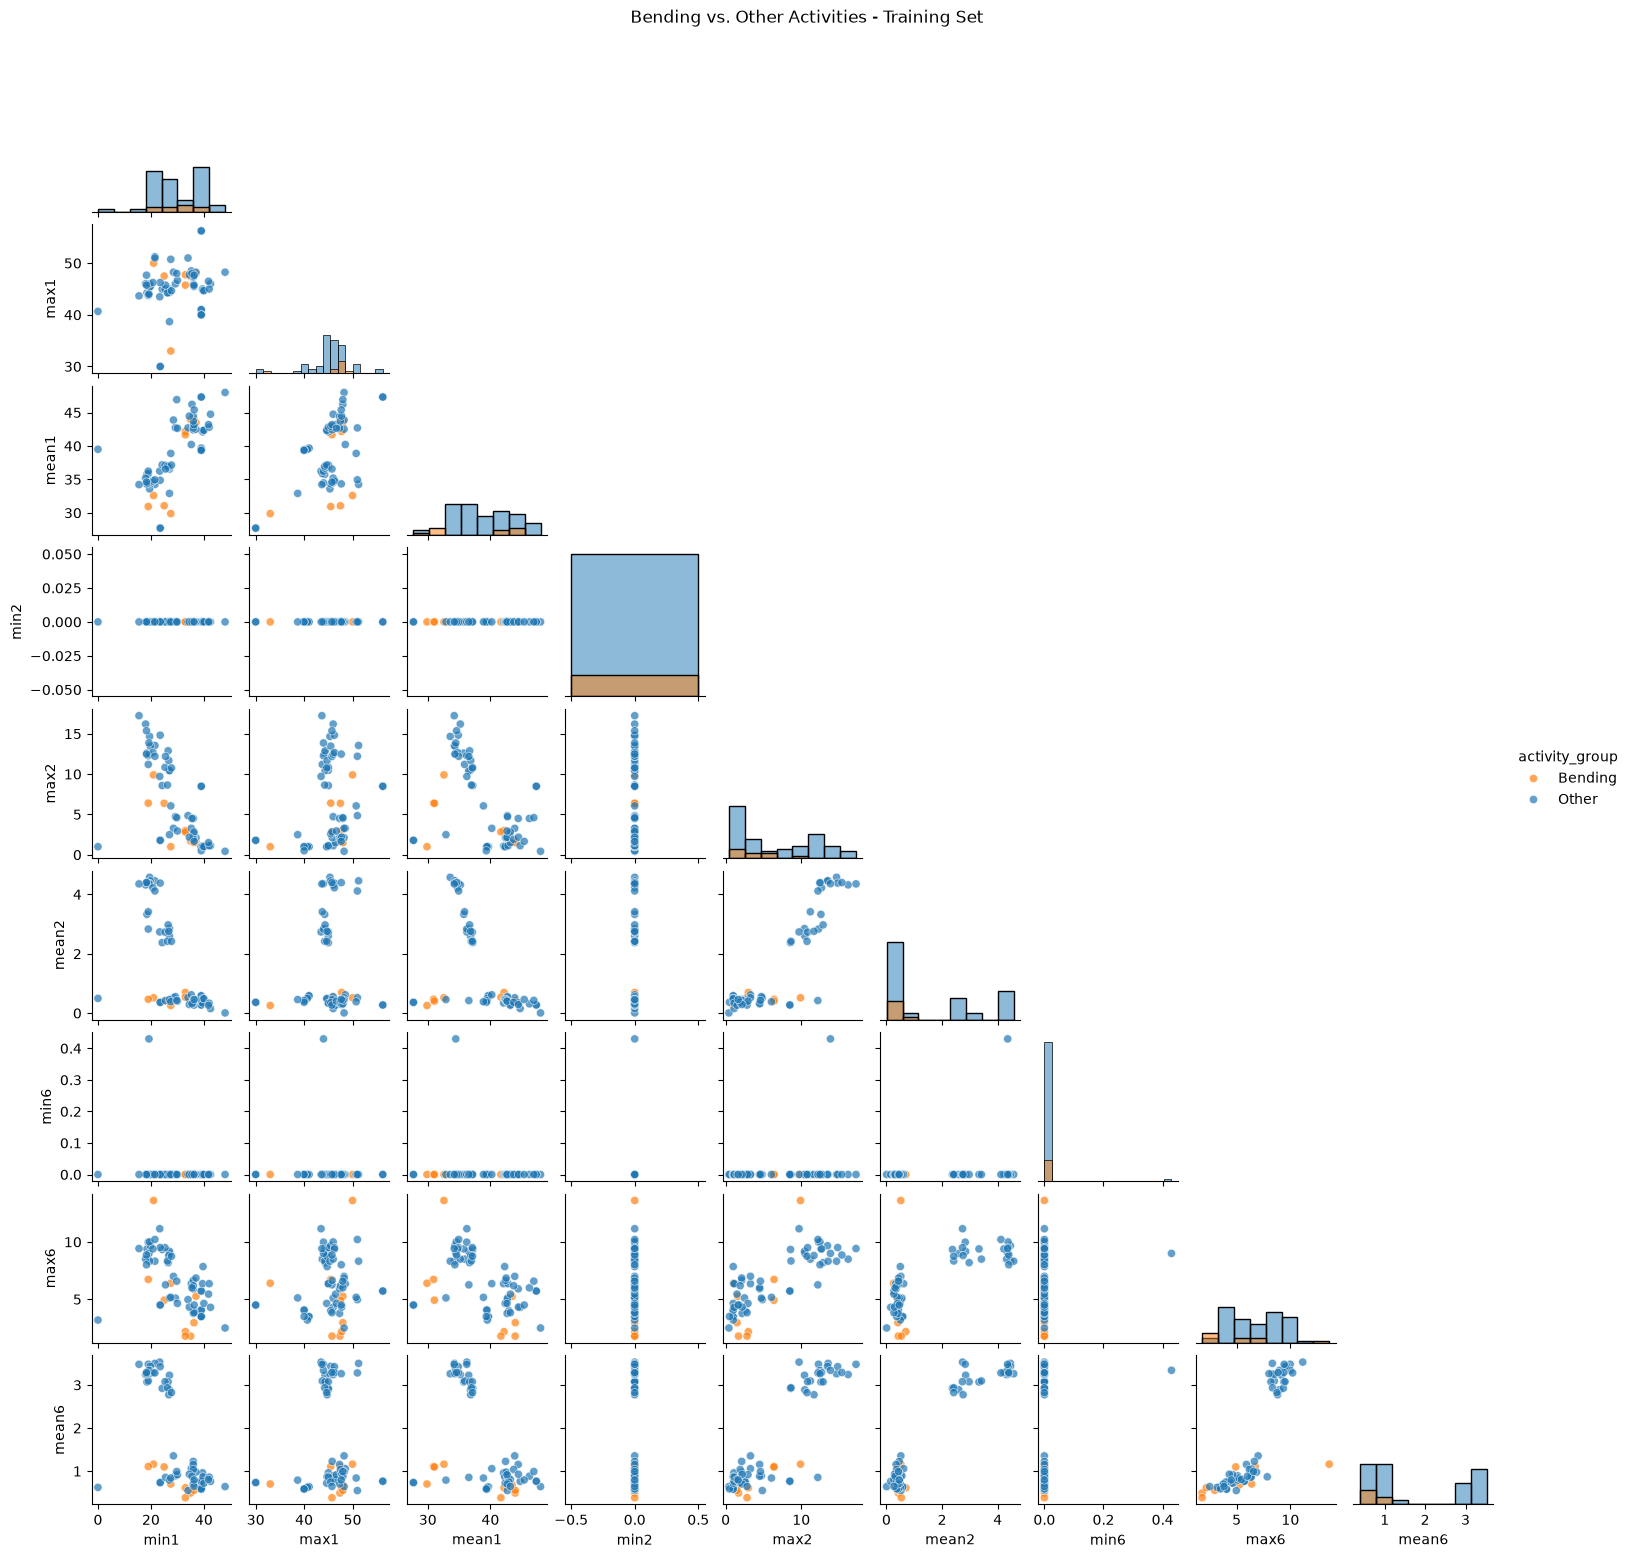

In [23]:
g = sns.pairplot(
    data=plot_df,
    vars=selected_features,
    hue="activity_group",
    hue_order=["Bending", "Other"],
    palette={
        "Bending": "tab:orange",
        "Other": "tab:blue"
    },
    diag_kind="hist",
    corner=True,
    height=1.7,
    plot_kws={
        "alpha": 0.7,
        "s":35
    }
)

g.fig.suptitle(
    "Bending vs. Other Activities - Training Set",
    y=1.02
)

plt.show()

The scatter plots compare the minimum, maximum, and mean features extracted from time series 1, 2, and 6 of the training instances. Bending1 and bending2 are combined into one class.

Bending instances generally have low mean2 and mean6 values, but overlap with other activities remains. The min2 feature is constant and provides no information for distinguishing the classes. Overall, some features appear useful for classification, although the plots do not show complete separation.

#### ii. Splitted Plots

In [24]:
split_feature_rows = []
split_file_names = []

for file_name, df in train_datasets.items():

    midpoint = len(df) // 2

    parts = [
        df.iloc[:midpoint],
        df.iloc[midpoint:]
    ]

    row_features = {}

    for part_number, part_df in enumerate(parts, start=1):

        for series_number in [1, 2, 6]:

            column_name = SENSOR_COLUMNS[series_number - 1]
            series = part_df[column_name]

            row_features[f"min{series_number}_part{part_number}"] = (
                series.min()
            )
            row_features[f"max{series_number}_part{part_number}"] = (
                series.max()
            )
            row_features[f"mean{series_number}_part{part_number}"] = (
                series.mean()
            )

    split_feature_rows.append(row_features)
    split_file_names.append(file_name)

split_plot_df = pd.DataFrame(
    split_feature_rows,
    index=split_file_names
)

split_plot_df.index.name = "file"

split_plot_df["activity_group"] = split_plot_df.index.map(
    lambda file_name: (
        "Bending"
        if file_name.split("/")[0] in ["bending1", "bending2"]
        else "Other"
    )
)

print("Plot data shape:", split_plot_df.shape)
display(split_plot_df.head())

Plot data shape: (69, 19)


,min1_part1,max1_part1,mean1_part1,min2_part1,max2_part1,mean2_part1,min6_part1,max6_part1,mean6_part1,min1_part2,max1_part2,mean1_part2,min2_part2,max2_part2,mean2_part2,min6_part2,max6_part2,mean6_part2,activity_group
file,,,,,,,,,,,,,,,,,,,
bending1/dataset3.csv,36.50,46.50,44.057167,0.0,1.50,0.381042,0.0,1.79,0.598250,35.00,47.40,43.851833,0.0,1.70,0.471458,0.0,1.50,0.388333,Bending
bending1/dataset4.csv,33.75,47.75,43.278875,0.0,3.00,0.673292,0.0,1.53,0.640958,33.00,46.00,41.080750,0.0,2.86,0.718792,0.0,2.18,0.586083,Bending
bending1/dataset5.csv,33.00,45.75,41.621208,0.0,2.83,0.623083,0.0,1.79,0.419083,39.25,43.67,41.734917,0.0,1.12,0.448875,0.0,1.50,0.347500,Bending
bending1/dataset6.csv,39.00,48.00,44.117042,0.0,1.30,0.250042,0.0,5.26,0.815417,37.00,46.50,42.792875,0.0,1.58,0.506125,0.0,4.06,0.543875,Bending
bending1/dataset7.csv,36.67,45.00,43.486208,0.0,1.30,0.378667,0.0,2.28,0.524875,36.25,48.00,44.452042,0.0,1.50,0.447583,0.0,2.96,0.585750,Bending


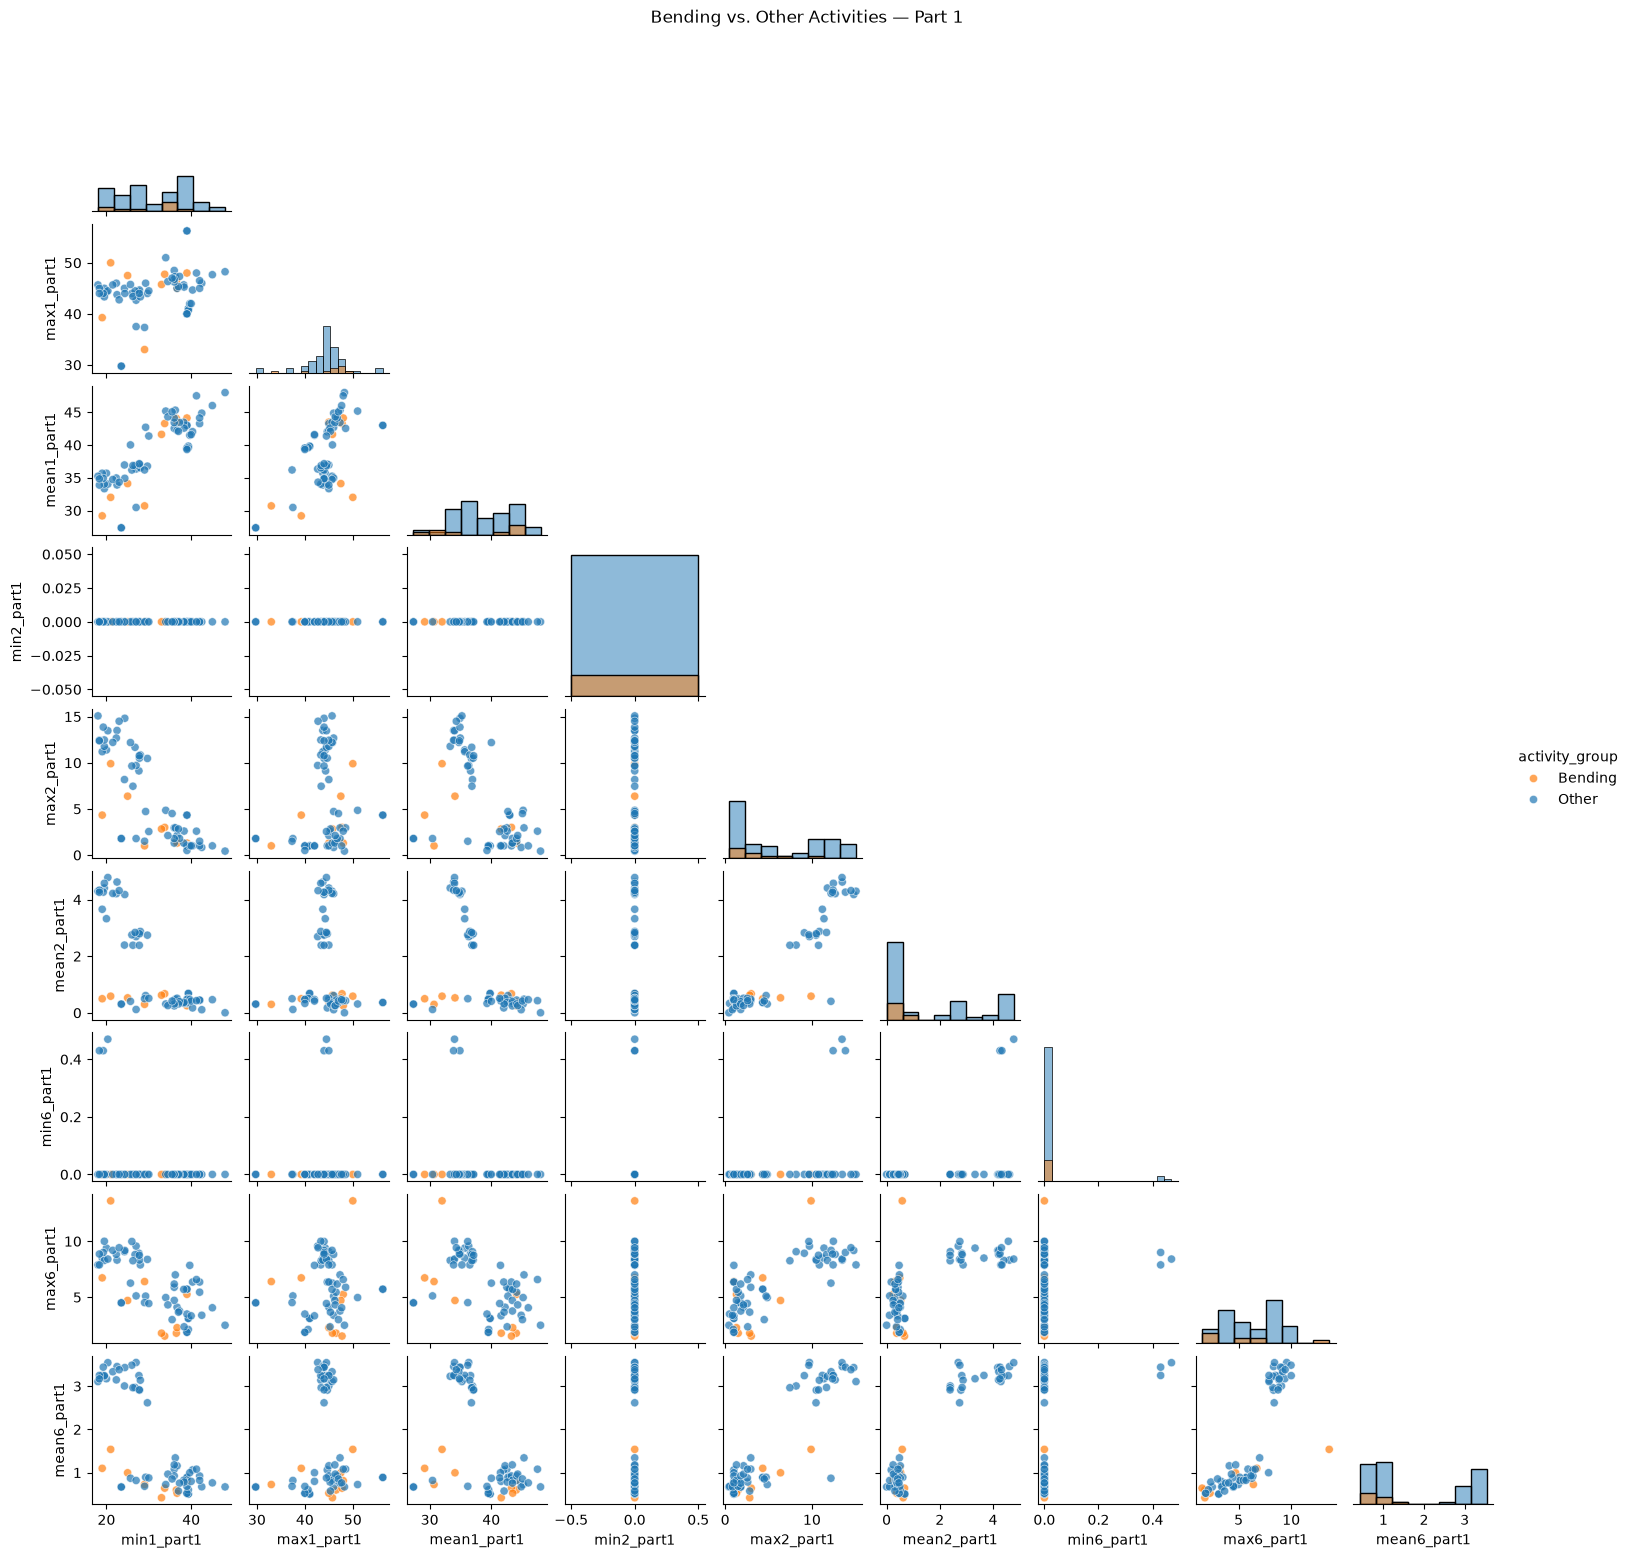

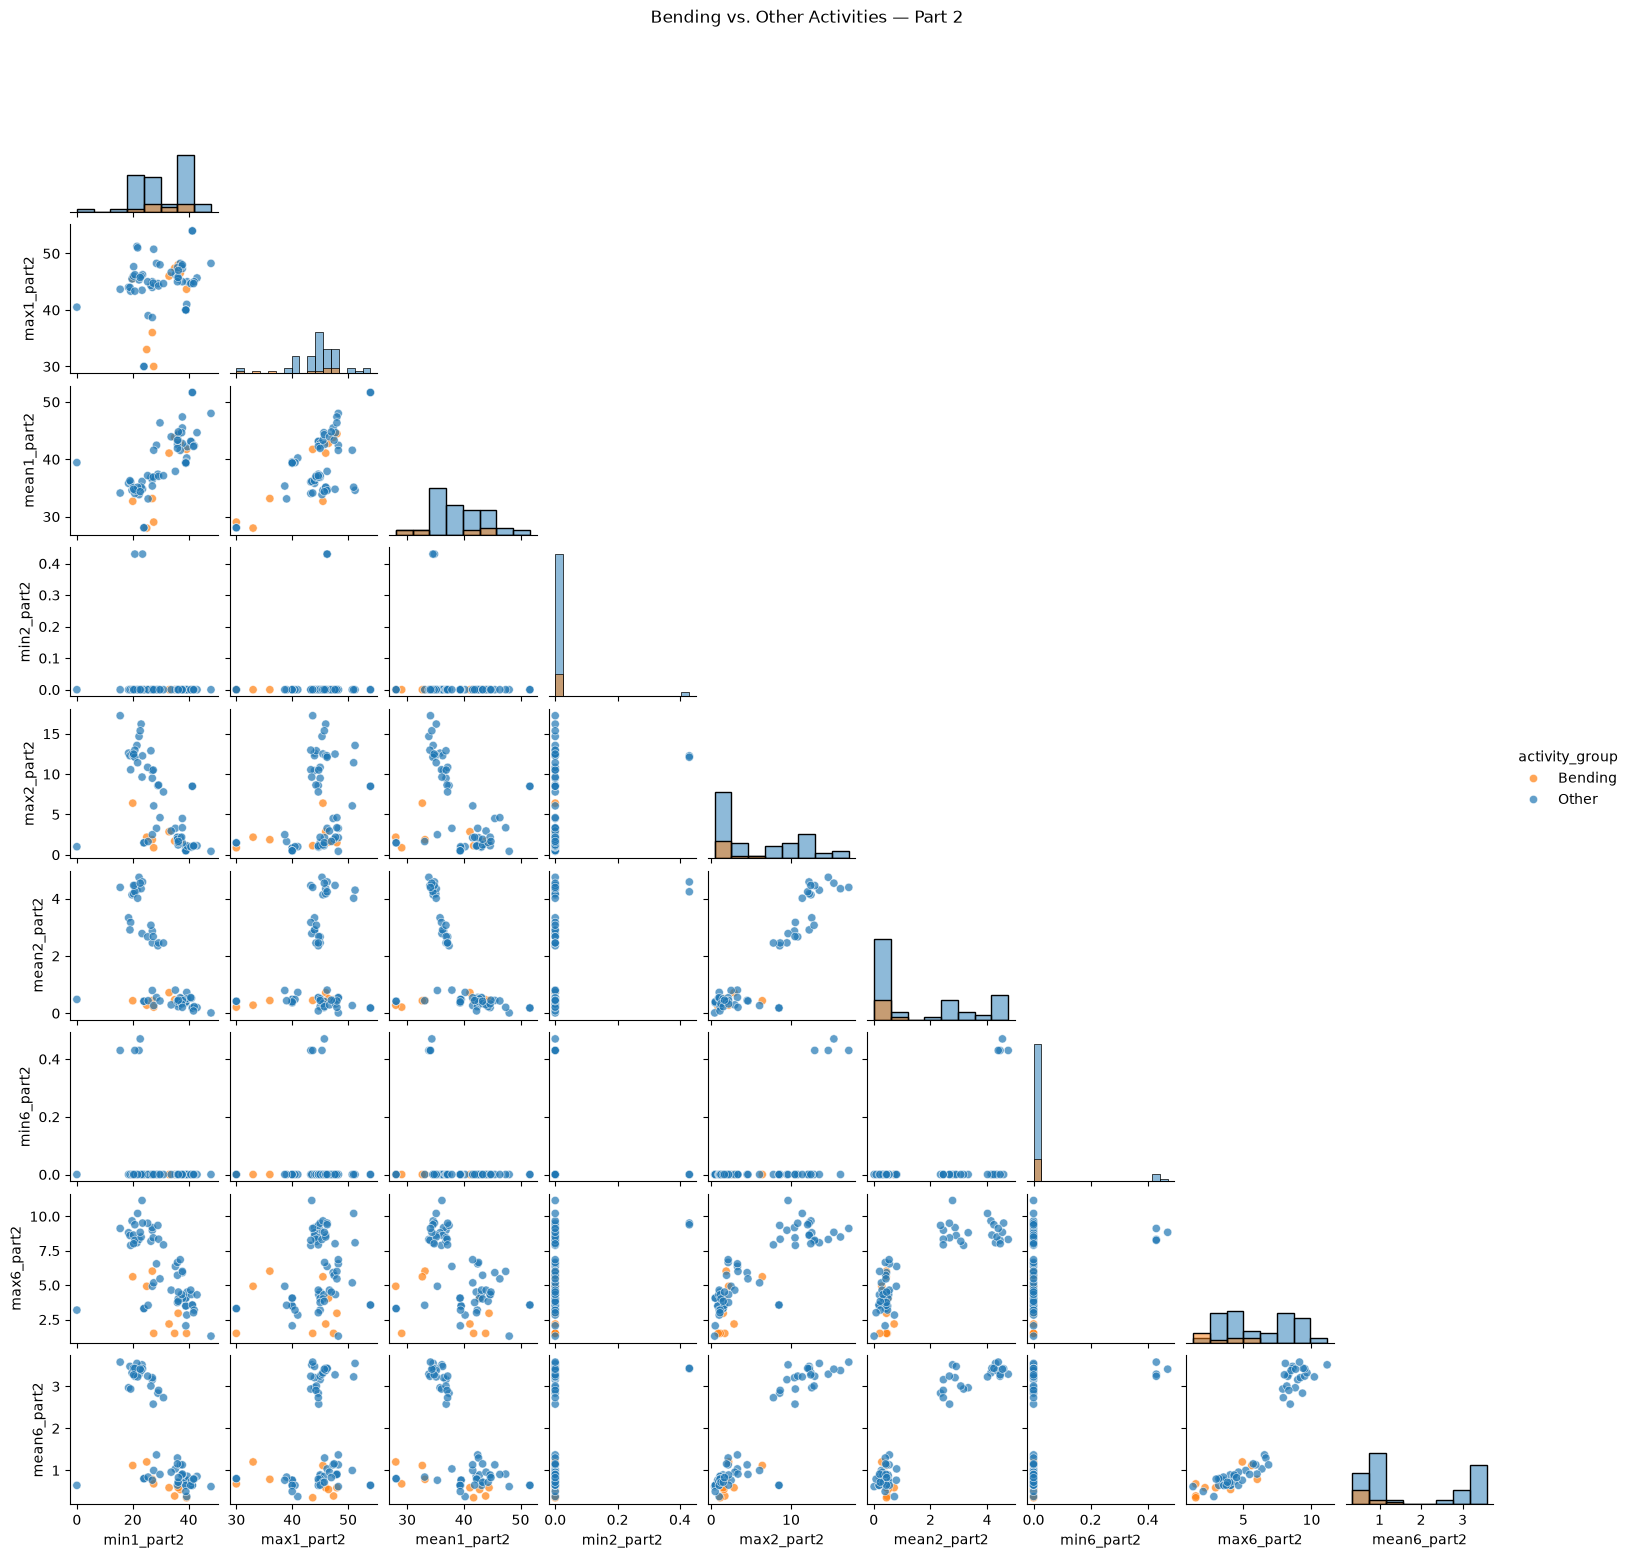

In [25]:
for part_number in [1, 2]:

    part_features = [
        f"{feature}{series_number}_part{part_number}"
        for series_number in [1, 2, 6]
        for feature in ["min", "max", "mean"]
    ]

    g = sns.pairplot(
        data=split_plot_df,
        vars=part_features,
        hue="activity_group",
        hue_order=["Bending", "Other"],
        palette={
            "Bending": "tab:orange",
            "Other": "tab:blue"
        },
        diag_kind="hist",
        corner=True,
        height=1.7,
        plot_kws={
            "alpha": 0.7,
            "s": 35
        }
    )

    g.fig.suptitle(
        f"Bending vs. Other Activities — Part {part_number}",
        y=1.02
    )

    plt.show()

The split-series plots show similar overall patterns to the original plots. In both halves, bending instances generally have low mean2 and mean6 values, but overlap with other activities remains.

Splitting reveals some differences between the two halves. For example, one bending instance has a particularly high max6 in the first half, while some other activities have nonzero min2 values in the second half. These details are not apparent from the full-series features alone.

#### iii. Time Series Segments

In [26]:
def extract_segment_features(datasets, n_segments):
    feature_rows = []
    file_names = []

    for file_name in sorted(datasets):
        df = datasets[file_name]
        row_features = {}

        # Divide row positions into consecutive segments
        segment_indices = np.array_split(
            np.arange(len(df)),
            n_segments
        )

        for part_number, positions in enumerate(
            segment_indices,
            start=1
        ):
            part_df = df.iloc[positions]

            for series_number, column_name in enumerate(
                SENSOR_COLUMNS,
                start=1
            ):
                series = part_df[column_name]

                statistics = {
                    "min": series.min(),
                    "max": series.max(),
                    "mean": series.mean(),
                    "median": series.median(),
                    "std": series.std(),
                    "first_quartile": series.quantile(0.25),
                    "third_quartile": series.quantile(0.75)
                }

                for statistic_name, value in statistics.items():
                    feature_name = (
                        f"{statistic_name}{series_number}"
                        f"_part{part_number}"
                    )

                    row_features[feature_name] = value

        feature_rows.append(row_features)
        file_names.append(file_name)

    result = pd.DataFrame(
        feature_rows,
        index=file_names
    )

    result.index.name = "file"

    return result

In [27]:
train_features_by_l = {}

for l in range(1, 21):
    train_features_by_l[l] = extract_segment_features(
        train_datasets,
        n_segments=l
    )

# Use the same row order as the feature tables
training_files = train_features_by_l[1].index

y_train_binary = pd.Series(
    [
        1 if file_name.split("/")[0] in ["bending1", "bending2"]
        else 0
        for file_name in training_files
    ],
    index=training_files,
    name="bending"
)

feature_shapes = pd.DataFrame(
    [
        {
            "l": l,
            "Instances": features.shape[0],
            "Features": features.shape[1]
        }
        for l, features in train_features_by_l.items()
    ]
)

display(feature_shapes)

display(
    y_train_binary.value_counts()
    .rename(index={0: "Other", 1: "Bending"})
)

,l,Instances,Features
0,1,69,42
1,2,69,84
2,3,69,126
3,4,69,168
4,5,69,210
5,6,69,252
6,7,69,294
7,8,69,336
8,9,69,378
9,10,69,420


bending
Other      60
Bending     9
Name: count, dtype: int64

In [28]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create reproducible stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Reuse the same instance splits for every value of l
cv_splits = list(
    cv.split(
        train_features_by_l[1],
        y_train_binary
    )
)

# Standardization is fitted separately within each training fold
base_estimator = Pipeline([
    ("scaler", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=1e6,
            solver="lbfgs",
            max_iter=2000
        )
    )
])

# Check class counts in the validation folds
fold_counts = []

for fold_number, (_, validation_indices) in enumerate(
    cv_splits,
    start=1
):
    validation_labels = y_train_binary.iloc[validation_indices]

    fold_counts.append({
        "Fold": fold_number,
        "Other": (validation_labels == 0).sum(),
        "Bending": (validation_labels == 1).sum()
    })

display(pd.DataFrame(fold_counts))

,Fold,Other,Bending
0,1,12,2
1,2,12,2
2,3,12,2
3,4,12,2
4,5,12,1


In [29]:
rfecv_models = {}
cv_result_tables = []
summary_rows = []

for l in range(1, 21):
    X = train_features_by_l[l]

    # Confirm that features and labels use the same row order
    assert X.index.equals(y_train_binary.index)

    selector = RFECV(
        estimator=base_estimator,
        step=1,
        min_features_to_select=1,
        cv=cv_splits,
        scoring="accuracy",
        importance_getter="named_steps.logistic.coef_",
        n_jobs=-1
    )

    selector.fit(X, y_train_binary)

    rfecv_models[l] = selector

    mean_scores = selector.cv_results_["mean_test_score"]
    std_scores = selector.cv_results_["std_test_score"]

    # With step=1, results correspond to p = 1, 2, ..., 42*l
    feature_counts = np.arange(1, X.shape[1] + 1)

    cv_result_tables.append(
        pd.DataFrame({
            "l": l,
            "p": feature_counts,
            "CV Accuracy": mean_scores,
            "CV Std": std_scores
        })
    )

    best_p_for_l = int(selector.n_features_)
    best_score_for_l = float(mean_scores[best_p_for_l - 1])

    summary_rows.append({
        "l": l,
        "Original Features": X.shape[1],
        "Selected Features": best_p_for_l,
        "CV Accuracy": best_score_for_l,
        "CV Std": float(std_scores[best_p_for_l - 1])
    })

    print(
        f"l={l:2d} | "
        f"selected features={best_p_for_l:3d} | "
        f"CV accuracy={best_score_for_l:.4f}",
        flush=True
    )

cv_pair_results = pd.concat(
    cv_result_tables,
    ignore_index=True
)

cv_summary_df = pd.DataFrame(summary_rows)

display(cv_summary_df)

l= 1 | selected features= 16 | CV accuracy=0.9857
l= 2 | selected features=  6 | CV accuracy=0.9714
l= 3 | selected features=  6 | CV accuracy=0.9429
l= 4 | selected features=  9 | CV accuracy=0.9571
l= 5 | selected features=  1 | CV accuracy=0.9571
l= 6 | selected features=  5 | CV accuracy=0.9571
l= 7 | selected features=  8 | CV accuracy=0.9571
l= 8 | selected features=  2 | CV accuracy=0.9714
l= 9 | selected features= 10 | CV accuracy=0.9429
l=10 | selected features=  8 | CV accuracy=0.9714
l=11 | selected features=  5 | CV accuracy=0.9571
l=12 | selected features=  1 | CV accuracy=0.9571
l=13 | selected features= 11 | CV accuracy=0.9429
l=14 | selected features=  3 | CV accuracy=0.9571
l=15 | selected features=  2 | CV accuracy=0.9571
l=16 | selected features=  8 | CV accuracy=0.9429
l=17 | selected features=  5 | CV accuracy=0.9714
l=18 | selected features=  3 | CV accuracy=0.9571
l=19 | selected features=  2 | CV accuracy=0.9714
l=20 | selected features=  5 | CV accuracy=0.9714


,l,Original Features,Selected Features,CV Accuracy,CV Std
0,1,42,16,0.985714,0.028571
1,2,84,6,0.971429,0.034993
2,3,126,6,0.942857,0.053452
3,4,168,9,0.957143,0.034993
4,5,210,1,0.957143,0.034993
5,6,252,5,0.957143,0.034993
6,7,294,8,0.957143,0.034993
7,8,336,2,0.971429,0.034993
8,9,378,10,0.942857,0.053452
9,10,420,8,0.971429,0.034993


In [30]:
ranked_summary = cv_summary_df.sort_values(
    by=["CV Accuracy", "Selected Features", "l"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(ranked_summary)

best_row = ranked_summary.iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["Selected Features"])
best_cv_accuracy = float(best_row["CV Accuracy"])

best_selector = rfecv_models[best_l]

best_selected_features = (
    train_features_by_l[best_l]
    .columns[best_selector.support_]
    .tolist()
)

print("Best l:", best_l)
print("Best p:", best_p)
print(f"Best CV accuracy: {best_cv_accuracy:.4f}")

display(
    pd.DataFrame({
        "Selected Feature": best_selected_features
    })
)

,l,Original Features,Selected Features,CV Accuracy,CV Std
0,1,42,16,0.985714,0.028571
1,8,336,2,0.971429,0.034993
2,19,798,2,0.971429,0.034993
3,17,714,5,0.971429,0.034993
4,20,840,5,0.971429,0.034993
5,2,84,6,0.971429,0.034993
6,10,420,8,0.971429,0.034993
7,5,210,1,0.957143,0.034993
8,12,504,1,0.957143,0.034993
9,15,630,2,0.957143,0.034993


Best l: 1
Best p: 16
Best CV accuracy: 0.9857


,Selected Feature
0,min1_part1
1,max1_part1
2,mean1_part1
3,third_quartile1_part1
4,max2_part1
5,max3_part1
6,third_quartile3_part1
7,max4_part1
8,median4_part1
9,first_quartile4_part1


In [31]:
best_selector.support_

array([ True,  True,  True, False, False, False,  True, False,  True,
       False, False, False, False, False, False,  True, False, False,
       False, False,  True, False,  True, False,  True, False,  True,
       False,  True,  True,  True, False, False,  True, False, False,
       False, False, False,  True,  True, False])

Five-fold stratified cross-validation is used to preserve the class proportions as closely as possible, ensuring that every validation fold contains bending instances. For each value of l, RFECV selects the number of features using mean validation accuracy.

The correct approach performs standardization, feature selection, and model fitting using only the training portion of each fold. Selecting features or fitting the scaler on the entire training dataset before cross-validation would allow information from the validation folds to influence the model and could produce overly optimistic scores. All segments from a recording remain part of the same instance.

The same folds are used for all values of l. The pair (l, p) with the highest mean cross-validation accuracy is selected, with ties resolved by preferring fewer features and then fewer segments. This score is used for model selection; the held-out test set remains reserved for the subsequent evaluation.

The best combination is (l, p) = (1, 16), with a mean five-fold cross-validation accuracy of 98.57% and a standard deviation of 2.86 percentage points. RFE retains 16 of the original 42 features, covering all six sensor time series.

The highest validation accuracy is achieved without splitting the recordings. Although segmentation adds temporal information, none of the tested segmented representations achieves a higher score. The best two-segment model achieves 97.14%, so the observed advantage of using the full recordings is relatively small.

These results support selecting the full-series representation with 16 features for the subsequent analysis. The reported accuracy is a model-selection score; performance on the held-out test set remains to be evaluated.

#### iv. Confusion Matrix

In [32]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

X_train_best = train_features_by_l[best_l]

# Predict class labels: 0 = Other, 1 = Bending
y_train_pred = best_selector.predict(X_train_best)

# Predict the probability of Bending
positive_class_index = list(best_selector.classes_).index(1)

y_train_probability = best_selector.predict_proba(
    X_train_best
)[:, positive_class_index]

train_accuracy = accuracy_score(
    y_train_binary,
    y_train_pred
)

train_auc = roc_auc_score(
    y_train_binary,
    y_train_probability
)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Training AUC: {train_auc:.4f}")

Training accuracy: 1.0000
Training AUC: 1.0000


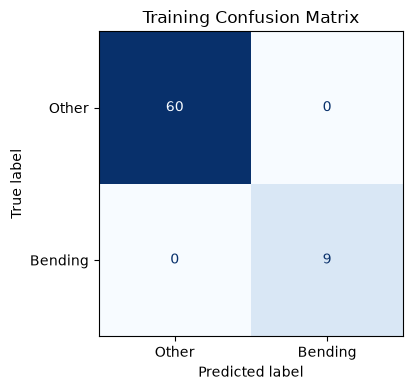

In [33]:
train_cm = confusion_matrix(
    y_train_binary,
    y_train_pred,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=["Other", "Bending"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Training Confusion Matrix")

plt.tight_layout()
plt.show()

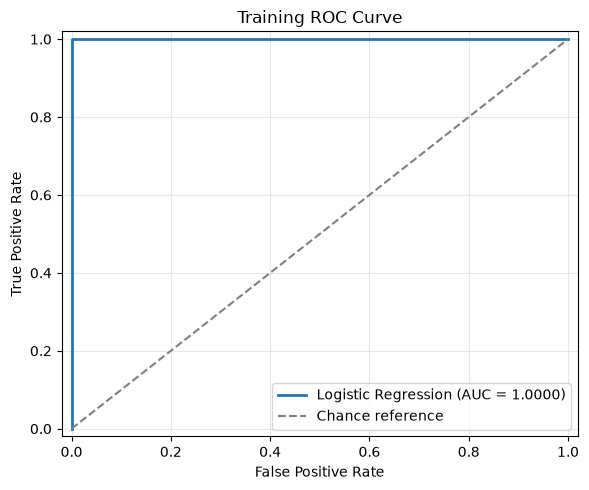

In [34]:
fpr, tpr, thresholds = roc_curve(
    y_train_binary,
    y_train_probability,
    pos_label=1
)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {train_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Training ROC Curve")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
best_pipeline = best_selector.estimator_

best_logistic = best_pipeline.named_steps["logistic"]

coefficient_table = pd.DataFrame({
    "Term": ["Intercept"] + best_selected_features,
    "Coefficient": np.concatenate([
        best_logistic.intercept_,
        best_logistic.coef_.ravel()
    ])
})

display(coefficient_table)

,Term,Coefficient
0,Intercept,-10.972780
1,min1_part1,-1.937793
2,max1_part1,1.709278
3,mean1_part1,-1.239359
4,third_quartile1_part1,-2.925989
5,max2_part1,-2.048019
6,max3_part1,0.751190
7,third_quartile3_part1,-2.292143
8,max4_part1,2.173464
9,median4_part1,-1.155283


In [36]:
# Scores before applying the logistic probability transformation
train_decision_scores = best_selector.decision_function(
    X_train_best
)

# Positive margins mean the point is on the correct side
signed_margins = (
    2 * y_train_binary.to_numpy() - 1
) * train_decision_scores

complete_separation = bool(
    np.all(signed_margins > 0)
)

print(
    "All training points strictly separated:",
    complete_separation
)
print(
    "Minimum signed margin:",
    signed_margins.min()
)

All training points strictly separated: True
Minimum signed margin: 5.676882569734424


In [37]:
parameter_table = coefficient_table.copy()

parameter_table["Wald p-value"] = np.nan

parameter_table["Inference status"] = (
    "N/A: complete separation"
)

display(parameter_table)

print(
    "Complete separation was confirmed. "
    "The unpenalized logistic model has no finite MLE, "
    "so conventional Wald p-values are not reported."
)

,Term,Coefficient,Wald p-value,Inference status
0,Intercept,-10.972780,NaN,N/A: complete separation
1,min1_part1,-1.937793,NaN,N/A: complete separation
2,max1_part1,1.709278,NaN,N/A: complete separation
3,mean1_part1,-1.239359,NaN,N/A: complete separation
4,third_quartile1_part1,-2.925989,NaN,N/A: complete separation
5,max2_part1,-2.048019,NaN,N/A: complete separation
6,max3_part1,0.751190,NaN,N/A: complete separation
7,third_quartile3_part1,-2.292143,NaN,N/A: complete separation
8,max4_part1,2.173464,NaN,N/A: complete separation
9,median4_part1,-1.155283,NaN,N/A: complete separation


Complete separation was confirmed. The unpenalized logistic model has no finite MLE, so conventional Wald p-values are not reported.


The classifier achieves 100% training accuracy, correctly classifying all 60 other-activity instances and all 9 bending instances. The ROC curve passes through the upper-left corner, with a training AUC of 1.0000. These are training results and do not establish performance on unseen data.

Complete separation is confirmed because every training instance has a positive signed margin, with a minimum of approximately 5.6769. Consequently, the unpenalized logistic regression model has no finite maximum likelihood estimate, and conventional Wald p-values cannot be reliably reported. They are therefore marked as N/A due to complete separation.

The reported coefficients correspond to standardized features from the fitted model with a very weak L2 penalty (C = 10⁶). They are retained for prediction, but should not be interpreted as finite unpenalized maximum likelihood estimates.

#### v. Test Classifier

In [38]:
# Extract test features using the selected number of segments
X_test_best = extract_segment_features(
    test_datasets,
    n_segments=best_l
)

# Confirm identical feature names and column order
assert X_test_best.columns.equals(X_train_best.columns)

# Create labels in the same order as the test feature rows
y_test_binary = pd.Series(
    [
        1 if file_name.split("/")[0] in ["bending1", "bending2"]
        else 0
        for file_name in X_test_best.index
    ],
    index=X_test_best.index,
    name="bending"
)

print("Test feature shape:", X_test_best.shape)

display(
    y_test_binary.value_counts()
    .rename(index={0: "Other", 1: "Bending"})
)

Test feature shape: (19, 42)


bending
Other      15
Bending     4
Name: count, dtype: int64

In [39]:
# Predict using the fitted selector, scaler, and classifier
y_test_pred = best_selector.predict(X_test_best)

test_accuracy = accuracy_score(
    y_test_binary,
    y_test_pred
)

test_error = 1 - test_accuracy

comparison_df = pd.DataFrame({
    "Evaluation": [
        "Training",
        "5-fold CV (model selection)",
        "Test"
    ],
    "Accuracy": [
        train_accuracy,
        best_cv_accuracy,
        test_accuracy
    ]
})

display(comparison_df)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test error: {test_error:.4f}")

accuracy_gap_pp = (
    test_accuracy - best_cv_accuracy
) * 100

print(
    "Test accuracy minus CV accuracy: "
    f"{accuracy_gap_pp:+.2f} percentage points"
)

,Evaluation,Accuracy
0,Training,1.000000
1,5-fold CV (model selection),0.985714
2,Test,1.000000


Test accuracy: 1.0000
Test error: 0.0000
Test accuracy minus CV accuracy: +1.43 percentage points


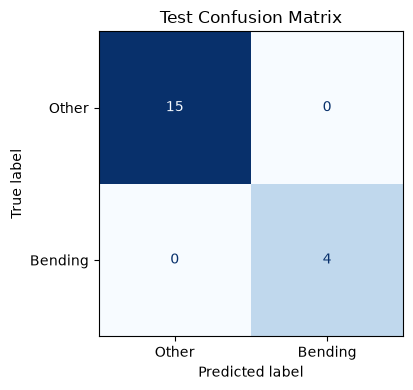

In [40]:
test_cm = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Other", "Bending"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

Using the selected configuration (l, p) = (1, 16), the classifier achieves 100% test accuracy and a test error of 0%. The confusion matrix shows that all 15 other-activity instances and all 4 bending instances are correctly classified.

The test accuracy is approximately 1.43 percentage points higher than the five-fold cross-validation accuracy of 98.57%, showing broadly consistent performance. However, the test set contains only 19 instances, so perfect classification on this set does not guarantee perfect performance on future data.

#### vi. Separation

Yes. Complete separation is confirmed in the selected 16-feature space: every training instance has a positive signed margin, with a minimum of approximately 5.6769.

Under complete separation, scaling the intercept and coefficients can continually increase the likelihood, so unpenalized logistic regression has no finite maximum likelihood estimate. This can lead to diverging coefficients and unreliable standard errors and p-values.

The fitted model produces finite coefficients because it retains a very weak L2 penalty (C = 10⁶) and uses numerical stopping criteria. Thus, the results establish a separation problem for unpenalized estimation, although they do not by themselves demonstrate a convergence failure in the fitted model.

#### vii. Imbalance

The class counts indicate imbalance: the original training set contains 60 other-activity instances and only 9 bending instances.

In [41]:
# Keep the feature set selected in 2(a)(iii)
X_train_selected = X_train_best.loc[
    :, best_selected_features
].copy()

X_test_selected = X_test_best.loc[
    :, best_selected_features
].copy()

# Keep all bending instances
case_files = y_train_binary.index[
    y_train_binary == 1
]

# Randomly sample the same number of other-activity instances
control_files = y_train_binary[
    y_train_binary == 0
].sample(
    n=len(case_files),
    replace=False,
    random_state=42
).index

case_control_index = case_files.append(control_files)

X_case_control = X_train_selected.loc[case_control_index]
y_case_control = y_train_binary.loc[case_control_index]

print("Case-control feature shape:", X_case_control.shape)

display(
    y_case_control.value_counts()
    .rename(index={0: "Other", 1: "Bending"})
)

Case-control feature shape: (18, 16)


bending
Bending    9
Other      9
Name: count, dtype: int64

In [42]:
from sklearn.base import clone

# Create a fresh copy of the scaler and logistic regression
case_control_model = clone(best_pipeline)

case_control_model.fit(
    X_case_control,
    y_case_control
)

# Save the intercept before correcting the class proportion
case_control_sample_intercept = (
    case_control_model
    .named_steps["logistic"]
    .intercept_
    .copy()
)

In [43]:
# Estimate the target prevalence from the original training set
pi_original = y_train_binary.mean()

# Bending proportion in the case-control sample
pi_sample = y_case_control.mean()

intercept_shift = (
    np.log(pi_original / (1 - pi_original))
    - np.log(pi_sample / (1 - pi_sample))
)

case_control_logistic = (
    case_control_model.named_steps["logistic"]
)

case_control_logistic.intercept_ = (
    case_control_sample_intercept + intercept_shift
)

print(f"Original training prevalence: {pi_original:.4f}")
print(f"Case-control sample prevalence: {pi_sample:.4f}")
print(f"Intercept adjustment: {intercept_shift:.4f}")

print(
    "Intercept before correction:",
    case_control_sample_intercept[0]
)

print(
    "Intercept after correction:",
    case_control_logistic.intercept_[0]
)

Original training prevalence: 0.1304
Case-control sample prevalence: 0.5000
Intercept adjustment: -1.8971
Intercept before correction: 0.5870198728941488
Intercept after correction: -1.3101001119917326


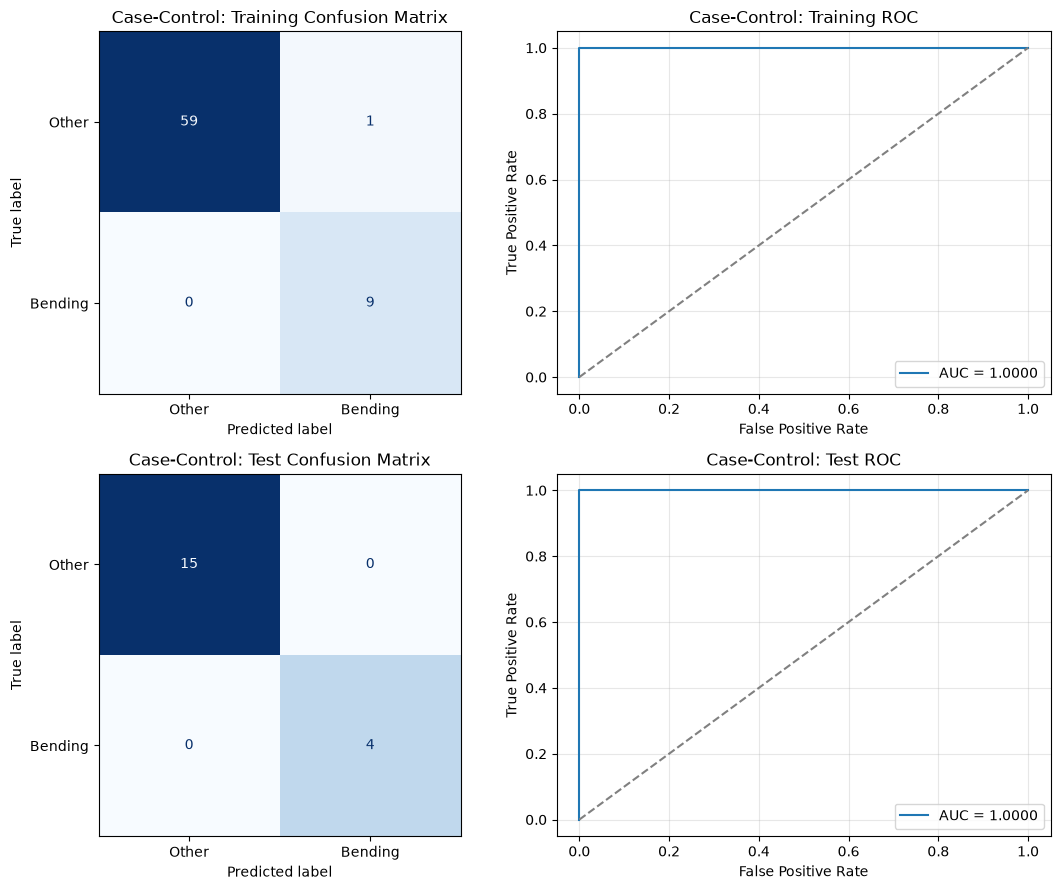

,Dataset,Accuracy,AUC
0,Training,0.985507,1.0
1,Test,1.000000,1.0


In [44]:
evaluation_sets = {
    "Training": (X_train_selected, y_train_binary),
    "Test": (X_test_selected, y_test_binary)
}

case_control_results = []

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 9)
)

for row_number, (set_name, data) in enumerate(
    evaluation_sets.items()
):
    X_eval, y_eval = data

    predictions = case_control_model.predict(X_eval)

    # Continuous scores for ROC and AUC
    scores = case_control_model.decision_function(X_eval)

    accuracy = accuracy_score(y_eval, predictions)
    auc_value = roc_auc_score(y_eval, scores)

    cm = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1]
    )

    case_control_results.append({
        "Dataset": set_name,
        "Accuracy": accuracy,
        "AUC": auc_value
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Other", "Bending"]
    ).plot(
        ax=axes[row_number, 0],
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    axes[row_number, 0].set_title(
        f"Case-Control: {set_name} Confusion Matrix"
    )

    fpr, tpr, _ = roc_curve(y_eval, scores)

    axes[row_number, 1].plot(
        fpr,
        tpr,
        label=f"AUC = {auc_value:.4f}"
    )

    axes[row_number, 1].plot(
        [0, 1], [0, 1],
        "--",
        color="gray"
    )

    axes[row_number, 1].set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title=f"Case-Control: {set_name} ROC"
    )

    axes[row_number, 1].legend(loc="lower right")
    axes[row_number, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

case_control_summary = pd.DataFrame(case_control_results)

display(case_control_summary)

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [45]:
import sklearn

from packaging.version import Version
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Search 17 values from 10^-4 to 10^4
l1_C_grid = np.logspace(-4, 4, 17)

# Configure L1 logistic regression
l1_options = {
    "solver": "liblinear",
    "max_iter": 10000,
    "random_state": 42
}

# Different sklearn versions use different parameter names
if Version(sklearn.__version__) >= Version("1.8"):
    l1_options["l1_ratio"] = 1.0
else:
    l1_options["penalty"] = "l1"

l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(**l1_options))
])

print("Candidate C values:")
print(l1_C_grid)

Candidate C values:
[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02 3.16227766e+02 1.00000000e+03 3.16227766e+03
 1.00000000e+04]


In [46]:
l1_searches = {}
l1_summary_rows = []

for l in range(1, 21):
    X = train_features_by_l[l]

    assert X.index.equals(y_train_binary.index)

    search = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={
            "logistic__C": l1_C_grid
        },
        scoring="accuracy",
        cv=cv_splits,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X, y_train_binary)

    l1_searches[l] = search

    fitted_logistic = (
        search.best_estimator_
        .named_steps["logistic"]
    )

    coefficients = fitted_logistic.coef_.ravel()

    nonzero_count = int(
        np.count_nonzero(coefficients)
    )

    best_C_for_l = float(
        search.best_params_["logistic__C"]
    )

    cv_std_for_l = float(
        search.cv_results_["std_test_score"][
            search.best_index_
        ]
    )

    l1_summary_rows.append({
        "l": l,
        "Original Features": X.shape[1],
        "Best C": best_C_for_l,
        "Nonzero Features": nonzero_count,
        "CV Accuracy": search.best_score_,
        "CV Std": cv_std_for_l
    })

    print(
        f"l={l:2d} | "
        f"C={best_C_for_l:.4g} | "
        f"nonzero features={nonzero_count:3d} | "
        f"CV accuracy={search.best_score_:.4f}",
        flush=True
    )

l1_summary_df = pd.DataFrame(l1_summary_rows)

display(l1_summary_df)

l= 1 | C=1e+04 | nonzero features= 36 | CV accuracy=0.9857
l= 2 | C=10 | nonzero features= 10 | CV accuracy=0.9714
l= 3 | C=0.3162 | nonzero features=  5 | CV accuracy=0.9571
l= 4 | C=1000 | nonzero features= 46 | CV accuracy=0.9571
l= 5 | C=31.62 | nonzero features= 17 | CV accuracy=0.9418
l= 6 | C=10 | nonzero features= 17 | CV accuracy=0.9571
l= 7 | C=31.62 | nonzero features= 20 | CV accuracy=0.9560
l= 8 | C=31.62 | nonzero features= 22 | CV accuracy=0.9429
l= 9 | C=1e+04 | nonzero features=273 | CV accuracy=0.9429
l=10 | C=100 | nonzero features= 32 | CV accuracy=0.9714
l=11 | C=1 | nonzero features=  8 | CV accuracy=0.9571
l=12 | C=1 | nonzero features=  9 | CV accuracy=0.9714
l=13 | C=1 | nonzero features= 11 | CV accuracy=0.9571
l=14 | C=1 | nonzero features= 12 | CV accuracy=0.9571
l=15 | C=316.2 | nonzero features= 71 | CV accuracy=0.9429
l=16 | C=100 | nonzero features= 46 | CV accuracy=0.9429
l=17 | C=31.62 | nonzero features= 28 | CV accuracy=0.9571
l=18 | C=1 | nonzero fe

,l,Original Features,Best C,Nonzero Features,CV Accuracy,CV Std
0,1,42,10000.000000,36,0.985714,0.028571
1,2,84,10.000000,10,0.971429,0.034993
2,3,126,0.316228,5,0.957143,0.057143
3,4,168,1000.000000,46,0.957143,0.034993
4,5,210,31.622777,17,0.941758,0.029199
5,6,252,10.000000,17,0.957143,0.034993
6,7,294,31.622777,20,0.956044,0.035946
7,8,336,31.622777,22,0.942857,0.053452
8,9,378,10000.000000,273,0.942857,0.053452
9,10,420,100.000000,32,0.971429,0.034993


In [47]:
l1_ranked_summary = l1_summary_df.sort_values(
    by=["CV Accuracy", "Best C", "l"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(l1_ranked_summary)

l1_best_row = l1_ranked_summary.iloc[0]

best_l1_l = int(l1_best_row["l"])
best_l1_C = float(l1_best_row["Best C"])
best_l1_cv_accuracy = float(
    l1_best_row["CV Accuracy"]
)

best_l1_model = (
    l1_searches[best_l1_l].best_estimator_
)

best_l1_coefficients = (
    best_l1_model
    .named_steps["logistic"]
    .coef_
    .ravel()
)

l1_coefficient_table = pd.DataFrame({
    "Feature": train_features_by_l[best_l1_l].columns,
    "Coefficient": best_l1_coefficients
})

l1_nonzero_table = l1_coefficient_table.loc[
    l1_coefficient_table["Coefficient"] != 0
].reset_index(drop=True)

print("Best l:", best_l1_l)
print("Best C:", best_l1_C)

print(
    f"Best CV accuracy: "
    f"{best_l1_cv_accuracy:.4f}"
)

print(
    "Number of nonzero features:",
    len(l1_nonzero_table)
)

display(l1_nonzero_table)

,l,Original Features,Best C,Nonzero Features,CV Accuracy,CV Std
0,1,42,10000.000000,36,0.985714,0.028571
1,12,504,1.000000,9,0.971429,0.034993
2,20,840,3.162278,12,0.971429,0.034993
3,2,84,10.000000,10,0.971429,0.034993
4,10,420,100.000000,32,0.971429,0.034993
5,19,798,100.000000,45,0.971429,0.034993
6,3,126,0.316228,5,0.957143,0.057143
7,11,462,1.000000,8,0.957143,0.034993
8,13,546,1.000000,11,0.957143,0.034993
9,14,588,1.000000,12,0.957143,0.034993


Best l: 1
Best C: 10000.0
Best CV accuracy: 0.9857
Number of nonzero features: 36


,Feature,Coefficient
0,min1_part1,-2.549843
1,max1_part1,1.460430
2,mean1_part1,-0.338051
3,median1_part1,-0.604659
4,std1_part1,0.638588
5,first_quartile1_part1,-0.033830
6,third_quartile1_part1,-3.306724
7,max2_part1,-2.623258
8,mean2_part1,0.275300
9,median2_part1,0.863958


The initial search selected C = 10⁴, the upper boundary of the original grid. Additional larger C values are therefore evaluated using the same cross-validation folds. The original results are retained, and the extended-search results are reported separately.

In [48]:
l1_extra_C_grid = np.logspace(4.5, 6, 4)

l1_extra_searches = {}

# Create a separate dictionary for the combined search results
l1_extended_searches = l1_searches.copy()

for l in range(1, 21):
    X = train_features_by_l[l]

    extra_search = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={
            "logistic__C": l1_extra_C_grid
        },
        scoring="accuracy",
        cv=cv_splits,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    extra_search.fit(X, y_train_binary)

    l1_extra_searches[l] = extra_search

    # Compare the best original and additional candidates
    l1_extended_searches[l] = min(
        [l1_searches[l], extra_search],
        key=lambda result: (
            -result.best_score_,
            result.best_params_["logistic__C"]
        )
    )

    chosen_search = l1_extended_searches[l]

    print(
        f"l={l:2d} | "
        f"C={chosen_search.best_params_['logistic__C']:.4g} | "
        f"CV accuracy={chosen_search.best_score_:.4f}",
        flush=True
    )

l= 1 | C=1e+04 | CV accuracy=0.9857
l= 2 | C=10 | CV accuracy=0.9714
l= 3 | C=0.3162 | CV accuracy=0.9571
l= 4 | C=1000 | CV accuracy=0.9571
l= 5 | C=31.62 | CV accuracy=0.9418
l= 6 | C=10 | CV accuracy=0.9571
l= 7 | C=31.62 | CV accuracy=0.9560
l= 8 | C=31.62 | CV accuracy=0.9429
l= 9 | C=3.162e+04 | CV accuracy=0.9571
l=10 | C=100 | CV accuracy=0.9714
l=11 | C=1 | CV accuracy=0.9571
l=12 | C=1 | CV accuracy=0.9714
l=13 | C=1 | CV accuracy=0.9571
l=14 | C=1 | CV accuracy=0.9571
l=15 | C=316.2 | CV accuracy=0.9429
l=16 | C=100 | CV accuracy=0.9429
l=17 | C=31.62 | CV accuracy=0.9571
l=18 | C=1 | CV accuracy=0.9571
l=19 | C=100 | CV accuracy=0.9714
l=20 | C=3.162 | CV accuracy=0.9714


In [49]:
l1_extended_rows = []

for l, search in sorted(l1_extended_searches.items()):
    coefficients = (
        search.best_estimator_
        .named_steps["logistic"]
        .coef_
        .ravel()
    )

    search_stage = (
        "Original grid"
        if search is l1_searches[l]
        else "Additional C values"
    )

    l1_extended_rows.append({
        "l": l,
        "Original Features": train_features_by_l[l].shape[1],
        "Best C": float(
            search.best_params_["logistic__C"]
        ),
        "Nonzero Features": int(
            np.count_nonzero(coefficients)
        ),
        "CV Accuracy": search.best_score_,
        "CV Std": float(
            search.cv_results_["std_test_score"][
                search.best_index_
            ]
        ),
        "Selected From": search_stage
    })

l1_extended_summary_df = pd.DataFrame(l1_extended_rows)

l1_extended_ranked_summary = (
    l1_extended_summary_df
    .sort_values(
        by=["CV Accuracy", "Best C", "l"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

display(l1_extended_ranked_summary)

,l,Original Features,Best C,Nonzero Features,CV Accuracy,CV Std,Selected From
0,1,42,10000.000000,36,0.985714,0.028571,Original grid
1,12,504,1.000000,9,0.971429,0.034993,Original grid
2,20,840,3.162278,12,0.971429,0.034993,Original grid
3,2,84,10.000000,10,0.971429,0.034993,Original grid
4,10,420,100.000000,32,0.971429,0.034993,Original grid
5,19,798,100.000000,45,0.971429,0.034993,Original grid
6,3,126,0.316228,5,0.957143,0.057143,Original grid
7,11,462,1.000000,8,0.957143,0.034993,Original grid
8,13,546,1.000000,11,0.957143,0.034993,Original grid
9,14,588,1.000000,12,0.957143,0.034993,Original grid


In [50]:
l1_extended_best_row = l1_extended_ranked_summary.iloc[0]

best_l1_extended_l = int(l1_extended_best_row["l"])
best_l1_extended_C = float(l1_extended_best_row["Best C"])

best_l1_extended_cv_accuracy = float(
    l1_extended_best_row["CV Accuracy"]
)

best_l1_extended_model = (
    l1_extended_searches[best_l1_extended_l]
    .best_estimator_
)

extended_coefficients = (
    best_l1_extended_model
    .named_steps["logistic"]
    .coef_
    .ravel()
)

l1_extended_coefficient_table = pd.DataFrame({
    "Feature": (
        train_features_by_l[best_l1_extended_l].columns
    ),
    "Coefficient": extended_coefficients
})

l1_extended_nonzero_table = (
    l1_extended_coefficient_table.loc[
        l1_extended_coefficient_table["Coefficient"] != 0
    ]
    .reset_index(drop=True)
)

print("Best l after extension:", best_l1_extended_l)
print("Best C after extension:", best_l1_extended_C)

print(
    "Best CV accuracy after extension:",
    f"{best_l1_extended_cv_accuracy:.4f}"
)

print(
    "Number of nonzero features:",
    len(l1_extended_nonzero_table)
)

display(l1_extended_nonzero_table)

Best l after extension: 1
Best C after extension: 10000.0
Best CV accuracy after extension: 0.9857
Number of nonzero features: 36


,Feature,Coefficient
0,min1_part1,-2.549843
1,max1_part1,1.460430
2,mean1_part1,-0.338051
3,median1_part1,-0.604659
4,std1_part1,0.638588
5,first_quartile1_part1,-0.033830
6,third_quartile1_part1,-3.306724
7,max2_part1,-2.623258
8,mean2_part1,0.275300
9,median2_part1,0.863958


#### ii. Comparison

In [51]:
# Training features for the selected L1 configuration
l1_X_train = train_features_by_l[best_l1_extended_l]

# Extract test features using the same segmentation
l1_X_test = extract_segment_features(
    test_datasets,
    n_segments=best_l1_extended_l
)

# Check feature columns and label alignment
assert l1_X_test.columns.equals(l1_X_train.columns)
assert l1_X_train.index.equals(y_train_binary.index)
assert l1_X_test.index.equals(y_test_binary.index)

# Evaluate the already fitted L1 model
l1_train_pred = best_l1_extended_model.predict(l1_X_train)
l1_test_pred = best_l1_extended_model.predict(l1_X_test)

l1_train_accuracy = accuracy_score(
    y_train_binary,
    l1_train_pred
)

l1_test_accuracy = accuracy_score(
    y_test_binary,
    l1_test_pred
)

l1_test_error = 1 - l1_test_accuracy

print(f"L1 training accuracy: {l1_train_accuracy:.4f}")
print(f"L1 test accuracy: {l1_test_accuracy:.4f}")
print(f"L1 test error: {l1_test_error:.4f}")

L1 training accuracy: 1.0000
L1 test accuracy: 1.0000
L1 test error: 0.0000


In [52]:
binary_method_comparison = pd.DataFrame({
    "Method": [
        "Logistic Regression + RFE",
        "L1 Logistic Regression"
    ],
    "Best l": [
        best_l,
        best_l1_extended_l
    ],
    "Features Used": [
        best_p,
        len(l1_extended_nonzero_table)
    ],
    "CV Accuracy": [
        best_cv_accuracy,
        best_l1_extended_cv_accuracy
    ],
    "Training Accuracy": [
        train_accuracy,
        l1_train_accuracy
    ],
    "Test Accuracy": [
        test_accuracy,
        l1_test_accuracy
    ],
    "Test Error": [
        1 - test_accuracy,
        l1_test_error
    ]
})

display(binary_method_comparison)

,Method,Best l,Features Used,CV Accuracy,Training Accuracy,Test Accuracy,Test Error
0,Logistic Regression + RFE,1,16,0.985714,1.0,1.0,0.0
1,L1 Logistic Regression,1,36,0.985714,1.0,1.0,0.0


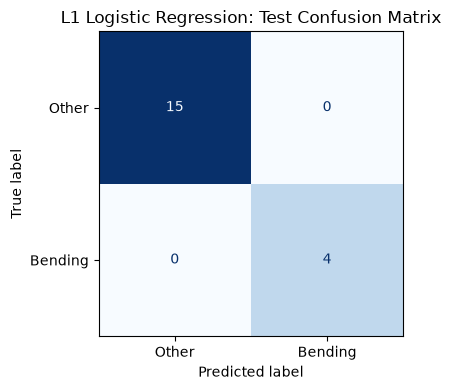

In [53]:
l1_test_cm = confusion_matrix(
    y_test_binary,
    l1_test_pred,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=l1_test_cm,
    display_labels=["Other", "Bending"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("L1 Logistic Regression: Test Confusion Matrix")

plt.tight_layout()
plt.show()

The earlier variable-selection approach uses RFE, the alternative permitted in 2(a)(iii). Both RFE and L1-penalized logistic regression achieve a CV accuracy of 98.57%, training accuracy of 100%, and test accuracy of 100%. Both correctly classify all 15 other-activity instances and all 4 bending instances in the test set. Neither method shows better predictive accuracy in this experiment.

RFE produces a more compact model, retaining 16 features compared with 36 nonzero features for L1. The selected L1 model uses a large C, corresponding to weak regularization and limited sparsity.

L1 is more straightforward to implement because coefficient estimation and feature selection occur during the same fitting process, whereas RFE requires repeated feature elimination. Thus, RFE provides the smaller model here, while L1 offers a simpler feature-selection workflow.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [54]:
multiclass_train_files = train_features_by_l[1].index

multiclass_test_files = pd.Index(
    sorted(test_datasets),
    name="file"
)

y_train_multiclass = pd.Series(
    [
        file_name.split("/")[0]
        for file_name in multiclass_train_files
    ],
    index=multiclass_train_files,
    name="activity"
)

y_test_multiclass = pd.Series(
    [
        file_name.split("/")[0]
        for file_name in multiclass_test_files
    ],
    index=multiclass_test_files,
    name="activity"
)

multiclass_classes = sorted(
    y_train_multiclass.unique()
)

multiclass_class_counts = pd.concat(
    [
        y_train_multiclass.value_counts().rename("Training"),
        y_test_multiclass.value_counts().rename("Test")
    ],
    axis=1
).fillna(0).astype(int).sort_index()

display(multiclass_class_counts)

assert len(multiclass_classes) == 7
assert len(y_train_multiclass) == 69
assert len(y_test_multiclass) == 19

,Training,Test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


In [55]:
from sklearn.model_selection import StratifiedKFold

multiclass_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

multiclass_cv_splits = list(
    multiclass_cv.split(
        train_features_by_l[1],
        y_train_multiclass
    )
)

# Display class counts in each validation fold
multiclass_fold_counts = pd.DataFrame([
    y_train_multiclass.iloc[validation_indices]
    .value_counts()
    .reindex(multiclass_classes, fill_value=0)

    for _, validation_indices in multiclass_cv_splits
])

multiclass_fold_counts.index = pd.RangeIndex(
    1,
    len(multiclass_cv_splits) + 1,
    name="Fold"
)

display(multiclass_fold_counts)

# Every training fold must contain all seven classes
for training_indices, _ in multiclass_cv_splits:
    assert (
        y_train_multiclass.iloc[training_indices].nunique()
        == 7
    )

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


activity,bending1,bending2,cycling,lying,sitting,standing,walking
Fold,,,,,,,
1,1,1,3,2,2,3,2
2,1,1,2,3,2,3,2
3,1,1,2,3,2,2,3
4,1,1,2,2,3,2,3
5,1,0,3,2,3,2,2


In [56]:
# Reuse the version-compatible L1 settings
multiclass_options = l1_options.copy()

multiclass_options.update({
    "solver": "saga",
    "max_iter": 10000,
    "tol": 1e-3
})

multiclass_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "logistic",
        LogisticRegression(**multiclass_options)
    )
])

multiclass_C_grid = np.logspace(-4, 4, 17)

In [57]:
multiclass_first_search = GridSearchCV(
    estimator=multiclass_pipeline,
    param_grid={
        "logistic__C": multiclass_C_grid
    },
    scoring="accuracy",
    cv=multiclass_cv_splits,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

multiclass_first_search.fit(
    train_features_by_l[1],
    y_train_multiclass
)

# Retain this result for the subsequent search
multiclass_searches = {
    1: multiclass_first_search
}

multiclass_first_logistic = (
    multiclass_first_search.best_estimator_
    .named_steps["logistic"]
)

multiclass_first_coefficients = (
    multiclass_first_logistic.coef_
)

# A feature is used if any class has a nonzero coefficient
multiclass_first_used_features = np.any(
    multiclass_first_coefficients != 0,
    axis=0
)

multiclass_summary_rows = [{
    "l": 1,
    "Original Features": train_features_by_l[1].shape[1],
    "Best C": float(
        multiclass_first_search.best_params_["logistic__C"]
    ),
    "Features Used": int(
        multiclass_first_used_features.sum()
    ),
    "CV Accuracy": multiclass_first_search.best_score_,
    "CV Std": float(
        multiclass_first_search.cv_results_["std_test_score"][
            multiclass_first_search.best_index_
        ]
    )
}]

display(pd.DataFrame(multiclass_summary_rows))

print(
    "Coefficient matrix shape:",
    multiclass_first_coefficients.shape
)

print(
    "Iterations for the refitted model:",
    multiclass_first_logistic.n_iter_
)

,l,Original Features,Best C,Features Used,CV Accuracy,CV Std
0,1,42,3.162278,33,0.898901,0.034154


Coefficient matrix shape: (7, 42)
Iterations for the refitted model: [323]


In [58]:
# Preserve the initial l=1 summary
multiclass_initial_summary_df = pd.DataFrame(
    multiclass_summary_rows
).copy()

for l in range(2, 21):
    X = train_features_by_l[l]

    assert X.index.equals(y_train_multiclass.index)

    search = GridSearchCV(
        estimator=multiclass_pipeline,
        param_grid={
            "logistic__C": multiclass_C_grid
        },
        scoring="accuracy",
        cv=multiclass_cv_splits,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X, y_train_multiclass)

    multiclass_searches[l] = search

    coefficients = (
        search.best_estimator_
        .named_steps["logistic"]
        .coef_
    )

    used_feature_count = int(
        np.any(coefficients != 0, axis=0).sum()
    )

    print(
        f"l={l:2d} | "
        f"C={search.best_params_['logistic__C']:.4g} | "
        f"features used={used_feature_count:3d} | "
        f"CV accuracy={search.best_score_:.4f}",
        flush=True
    )

l= 2 | C=31.62 | features used= 83 | CV accuracy=0.9286
l= 3 | C=3.162 | features used=104 | CV accuracy=0.8429
l= 4 | C=3.162 | features used=140 | CV accuracy=0.8560
l= 5 | C=31.62 | features used=210 | CV accuracy=0.8703
l= 6 | C=10 | features used=249 | CV accuracy=0.8418
l= 7 | C=31.62 | features used=294 | CV accuracy=0.8418
l= 8 | C=31.62 | features used=336 | CV accuracy=0.8560
l= 9 | C=31.62 | features used=378 | CV accuracy=0.8418
l=10 | C=31.62 | features used=420 | CV accuracy=0.8264
l=11 | C=10 | features used=453 | CV accuracy=0.7989
l=12 | C=100 | features used=504 | CV accuracy=0.8110
l=13 | C=316.2 | features used=546 | CV accuracy=0.7978
l=14 | C=1 | features used=284 | CV accuracy=0.7824
l=15 | C=31.62 | features used=630 | CV accuracy=0.8121
l=16 | C=3.162 | features used=490 | CV accuracy=0.7681
l=17 | C=1 | features used=296 | CV accuracy=0.8418
l=18 | C=10 | features used=733 | CV accuracy=0.8560
l=19 | C=1 | features used=333 | CV accuracy=0.7846
l=20 | C=1 | fe

In [59]:
multiclass_all_rows = []

for l, search in sorted(multiclass_searches.items()):
    coefficients = (
        search.best_estimator_
        .named_steps["logistic"]
        .coef_
    )

    multiclass_all_rows.append({
        "l": l,
        "Original Features": train_features_by_l[l].shape[1],
        "Best C": float(
            search.best_params_["logistic__C"]
        ),
        "Features Used": int(
            np.any(coefficients != 0, axis=0).sum()
        ),
        "CV Accuracy": search.best_score_,
        "CV Std": float(
            search.cv_results_["std_test_score"][
                search.best_index_
            ]
        )
    })

multiclass_summary_df = pd.DataFrame(multiclass_all_rows)

multiclass_ranked_summary = (
    multiclass_summary_df
    .sort_values(
        by=["CV Accuracy", "Best C", "l"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

display(multiclass_ranked_summary)

,l,Original Features,Best C,Features Used,CV Accuracy,CV Std
0,2,84,31.622777,83,0.928571,0.045175
1,1,42,3.162278,33,0.898901,0.034154
2,5,210,31.622777,210,0.870330,0.069117
3,4,168,3.162278,140,0.856044,0.077268
4,18,756,10.000000,733,0.856044,0.089505
5,8,336,31.622777,336,0.856044,0.062686
6,3,126,3.162278,104,0.842857,0.104978
7,17,714,1.000000,296,0.841758,0.104100
8,6,252,10.000000,249,0.841758,0.082190
9,7,294,31.622777,294,0.841758,0.051707


In [60]:
multiclass_best_row = multiclass_ranked_summary.iloc[0]

best_multiclass_l = int(multiclass_best_row["l"])
best_multiclass_C = float(multiclass_best_row["Best C"])

best_multiclass_cv_accuracy = float(
    multiclass_best_row["CV Accuracy"]
)

best_multiclass_model = (
    multiclass_searches[best_multiclass_l]
    .best_estimator_
)

best_multiclass_coefficients = (
    best_multiclass_model
    .named_steps["logistic"]
    .coef_
)

best_multiclass_used_features = (
    train_features_by_l[best_multiclass_l]
    .columns[
        np.any(best_multiclass_coefficients != 0, axis=0)
    ]
)

print("Best l:", best_multiclass_l)
print("Best C:", best_multiclass_C)

print(
    f"Best CV accuracy: "
    f"{best_multiclass_cv_accuracy:.4f}"
)

print(
    "Number of features used:",
    len(best_multiclass_used_features)
)

Best l: 2
Best C: 31.622776601683793
Best CV accuracy: 0.9286
Number of features used: 83


In [61]:
multiclass_X_train = train_features_by_l[
    best_multiclass_l
]

multiclass_X_test = extract_segment_features(
    test_datasets,
    n_segments=best_multiclass_l
)

assert multiclass_X_test.columns.equals(
    multiclass_X_train.columns
)

assert multiclass_X_test.index.equals(
    y_test_multiclass.index
)

multiclass_train_pred = best_multiclass_model.predict(
    multiclass_X_train
)

multiclass_test_pred = best_multiclass_model.predict(
    multiclass_X_test
)

multiclass_test_probability = (
    best_multiclass_model.predict_proba(
        multiclass_X_test
    )
)

multiclass_train_accuracy = accuracy_score(
    y_train_multiclass,
    multiclass_train_pred
)

multiclass_test_accuracy = accuracy_score(
    y_test_multiclass,
    multiclass_test_pred
)

multiclass_test_error = 1 - multiclass_test_accuracy

multiclass_evaluation = pd.DataFrame({
    "Evaluation": [
        "Training",
        "5-fold CV (model selection)",
        "Test"
    ],
    "Accuracy": [
        multiclass_train_accuracy,
        best_multiclass_cv_accuracy,
        multiclass_test_accuracy
    ]
})

print("Test feature shape:", multiclass_X_test.shape)
display(multiclass_evaluation)

print(f"Test error: {multiclass_test_error:.4f}")

print(
    "Misclassified test instances:",
    int((y_test_multiclass != multiclass_test_pred).sum())
)

Test feature shape: (19, 84)


,Evaluation,Accuracy
0,Training,1.000000
1,5-fold CV (model selection),0.928571
2,Test,0.842105


Test error: 0.1579
Misclassified test instances: 3


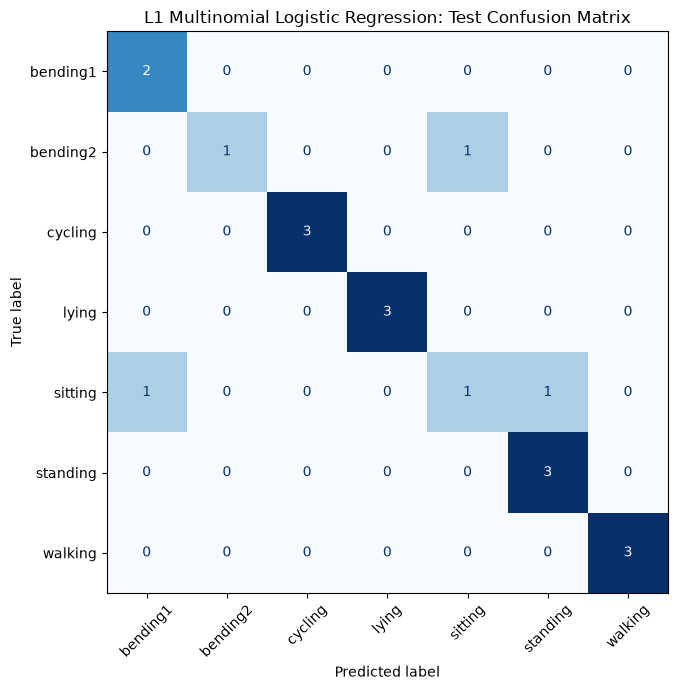

In [62]:
multiclass_model_classes = best_multiclass_model.classes_

multiclass_test_cm = confusion_matrix(
    y_test_multiclass,
    multiclass_test_pred,
    labels=multiclass_model_classes
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=multiclass_test_cm,
    display_labels=multiclass_model_classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title(
    "L1 Multinomial Logistic Regression: Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

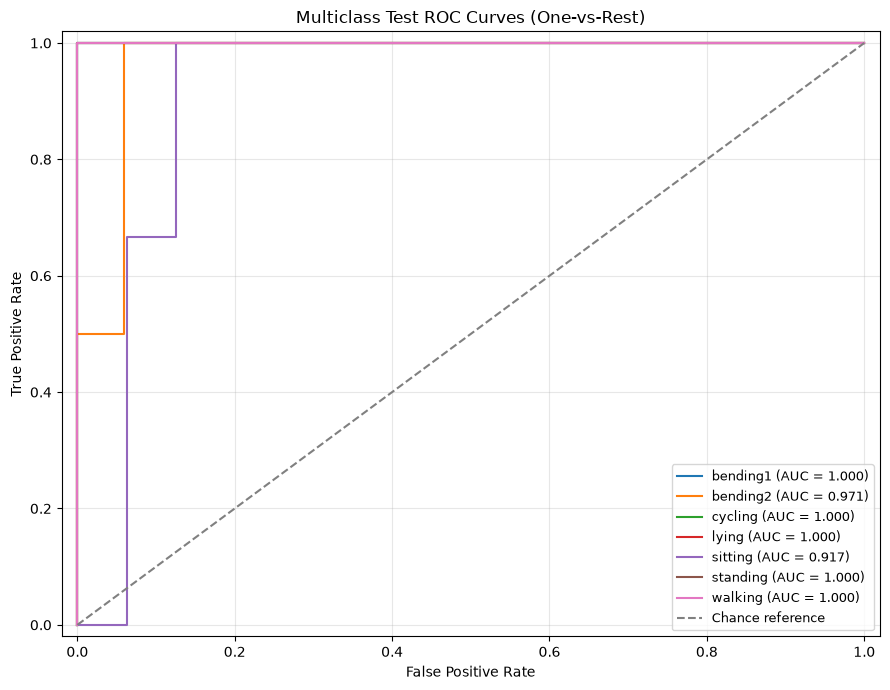

,Activity,Test Instances,OvR AUC
0,bending1,2,1.000000
1,bending2,2,0.970588
2,cycling,3,1.000000
3,lying,3,1.000000
4,sitting,3,0.916667
5,standing,3,1.000000
6,walking,3,1.000000


Macro-average OvR AUC: 0.9839


In [63]:
from sklearn.preprocessing import label_binarize

# Match indicator columns to the model's probability columns
multiclass_test_indicator = label_binarize(
    y_test_multiclass,
    classes=multiclass_model_classes
)

multiclass_auc_rows = []

fig, ax = plt.subplots(figsize=(9, 7))

for class_index, activity in enumerate(
    multiclass_model_classes
):
    actual_binary_labels = (
        multiclass_test_indicator[:, class_index]
    )

    activity_probability = (
        multiclass_test_probability[:, class_index]
    )

    fpr, tpr, _ = roc_curve(
        actual_binary_labels,
        activity_probability
    )

    activity_auc = roc_auc_score(
        actual_binary_labels,
        activity_probability
    )

    multiclass_auc_rows.append({
        "Activity": activity,
        "Test Instances": int(actual_binary_labels.sum()),
        "OvR AUC": activity_auc
    })

    ax.plot(
        fpr,
        tpr,
        label=f"{activity} (AUC = {activity_auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Chance reference"
)

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Multiclass Test ROC Curves (One-vs-Rest)",
    xlim=(-0.02, 1.02),
    ylim=(-0.02, 1.02)
)

ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

multiclass_auc_table = pd.DataFrame(
    multiclass_auc_rows
)

multiclass_macro_auc = (
    multiclass_auc_table["OvR AUC"].mean()
)

display(multiclass_auc_table)

print(f"Macro-average OvR AUC: {multiclass_macro_auc:.4f}")

The selected L1 multinomial logistic regression model uses l = 2 and C ≈ 31.62, with 83 of 84 features active in at least one class. It achieves 92.86% cross-validation accuracy and 100% training accuracy. Test accuracy is 84.21% (16 of 19 instances), corresponding to a test error of 15.79%.

The three test errors consist of one bending2 instance predicted as sitting, and two sitting instances predicted as bending1 and standing, respectively.

#### ii. Naive Bayes

In [64]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

nb_estimators = {
    "Gaussian NB": GaussianNB(
        var_smoothing=1e-9
    ),
    "Multinomial NB": MultinomialNB(
        alpha=1.0
    )
}

In [65]:
nb_cv_rows = []

for l in range(1, 21):
    X = train_features_by_l[l]

    assert X.index.equals(y_train_multiclass.index)

    # MultinomialNB requires nonnegative features
    assert np.all(X.to_numpy() >= 0)

    for model_name, estimator in nb_estimators.items():
        fold_scores = cross_val_score(
            estimator,
            X,
            y_train_multiclass,
            scoring="accuracy",
            cv=multiclass_cv_splits,
            n_jobs=-1,
            error_score="raise"
        )

        nb_cv_rows.append({
            "Model": model_name,
            "l": l,
            "Features": X.shape[1],
            "CV Accuracy": fold_scores.mean(),
            "CV Std": fold_scores.std()
        })

        print(
            f"{model_name:14s} | "
            f"l={l:2d} | "
            f"CV accuracy={fold_scores.mean():.4f}",
            flush=True
        )

nb_cv_results_df = pd.DataFrame(nb_cv_rows)

nb_ranked_summary = (
    nb_cv_results_df
    .sort_values(
        by=["Model", "CV Accuracy", "l"],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

display(nb_ranked_summary)

Gaussian NB    | l= 1 | CV accuracy=0.8571
Multinomial NB | l= 1 | CV accuracy=0.8549
Gaussian NB    | l= 2 | CV accuracy=0.8275
Multinomial NB | l= 2 | CV accuracy=0.7956
Gaussian NB    | l= 3 | CV accuracy=0.6813
Multinomial NB | l= 3 | CV accuracy=0.7967
Gaussian NB    | l= 4 | CV accuracy=0.7253
Multinomial NB | l= 4 | CV accuracy=0.7824
Gaussian NB    | l= 5 | CV accuracy=0.6527
Multinomial NB | l= 5 | CV accuracy=0.8121
Gaussian NB    | l= 6 | CV accuracy=0.6527
Multinomial NB | l= 6 | CV accuracy=0.7835
Gaussian NB    | l= 7 | CV accuracy=0.6956
Multinomial NB | l= 7 | CV accuracy=0.7835
Gaussian NB    | l= 8 | CV accuracy=0.6670
Multinomial NB | l= 8 | CV accuracy=0.7824
Gaussian NB    | l= 9 | CV accuracy=0.6385
Multinomial NB | l= 9 | CV accuracy=0.7835
Gaussian NB    | l=10 | CV accuracy=0.6813
Multinomial NB | l=10 | CV accuracy=0.7835
Gaussian NB    | l=11 | CV accuracy=0.6824
Multinomial NB | l=11 | CV accuracy=0.7824
Gaussian NB    | l=12 | CV accuracy=0.5945
Multinomial

,Model,l,Features,CV Accuracy,CV Std
0,Gaussian NB,1,42,0.857143,0.101015
1,Gaussian NB,2,84,0.827473,0.071352
2,Gaussian NB,4,168,0.725275,0.103379
3,Gaussian NB,7,294,0.695604,0.052998
4,Gaussian NB,11,462,0.682418,0.103984
5,Gaussian NB,3,126,0.681319,0.071640
6,Gaussian NB,10,420,0.681319,0.071640
7,Gaussian NB,8,336,0.667033,0.070758
8,Gaussian NB,5,210,0.652747,0.102934
9,Gaussian NB,6,252,0.652747,0.066880


In [66]:
nb_best_settings = (
    nb_ranked_summary
    .groupby("Model", sort=False)
    .head(1)
    .reset_index(drop=True)
)

display(nb_best_settings)

,Model,l,Features,CV Accuracy,CV Std
0,Gaussian NB,1,42,0.857143,0.101015
1,Multinomial NB,1,42,0.854945,0.045389


In [67]:
nb_fitted_models = {}
nb_test_predictions = {}
nb_test_probabilities = {}

nb_evaluation_rows = []

for _, row in nb_best_settings.iterrows():
    model_name = row["Model"]
    selected_l = int(row["l"])

    X_train_nb = train_features_by_l[selected_l]

    X_test_nb = extract_segment_features(
        test_datasets,
        n_segments=selected_l
    )

    assert X_test_nb.columns.equals(X_train_nb.columns)
    assert X_test_nb.index.equals(y_test_multiclass.index)
    assert np.all(X_test_nb.to_numpy() >= 0)

    fitted_model = clone(nb_estimators[model_name])

    fitted_model.fit(
        X_train_nb,
        y_train_multiclass
    )

    train_predictions = fitted_model.predict(X_train_nb)
    test_predictions = fitted_model.predict(X_test_nb)

    train_accuracy_nb = accuracy_score(
        y_train_multiclass,
        train_predictions
    )

    test_accuracy_nb = accuracy_score(
        y_test_multiclass,
        test_predictions
    )

    nb_fitted_models[model_name] = fitted_model
    nb_test_predictions[model_name] = test_predictions

    nb_test_probabilities[model_name] = (
        fitted_model.predict_proba(X_test_nb)
    )

    nb_evaluation_rows.append({
        "Model": model_name,
        "Best l": selected_l,
        "Features": X_train_nb.shape[1],
        "CV Accuracy": float(row["CV Accuracy"]),
        "Training Accuracy": train_accuracy_nb,
        "Test Accuracy": test_accuracy_nb,
        "Test Error": 1 - test_accuracy_nb
    })

nb_evaluation_table = pd.DataFrame(nb_evaluation_rows)

display(nb_evaluation_table)

,Model,Best l,Features,CV Accuracy,Training Accuracy,Test Accuracy,Test Error
0,Gaussian NB,1,42,0.857143,1.000000,0.894737,0.105263
1,Multinomial NB,1,42,0.854945,0.927536,0.894737,0.105263


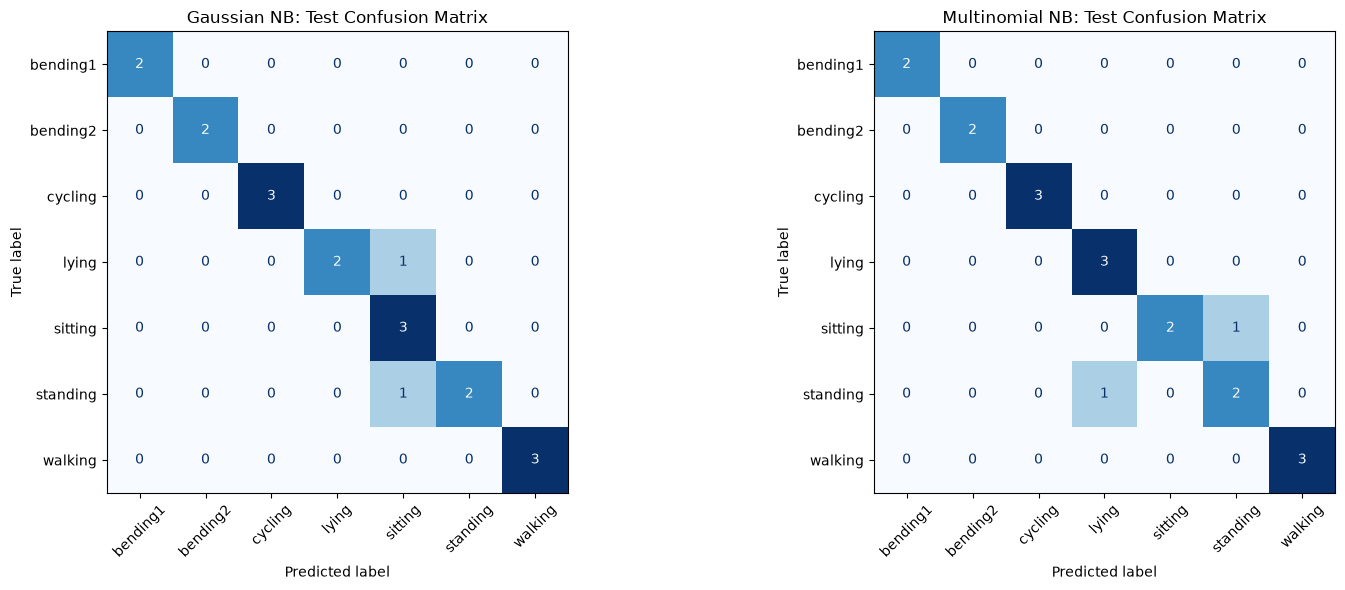

In [68]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for ax, (model_name, fitted_model) in zip(
    axes,
    nb_fitted_models.items()
):
    predictions = nb_test_predictions[model_name]
    classes = fitted_model.classes_

    cm = confusion_matrix(
        y_test_multiclass,
        predictions,
        labels=classes
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=45,
        colorbar=False
    )

    ax.set_title(f"{model_name}: Test Confusion Matrix")

plt.tight_layout()
plt.show()

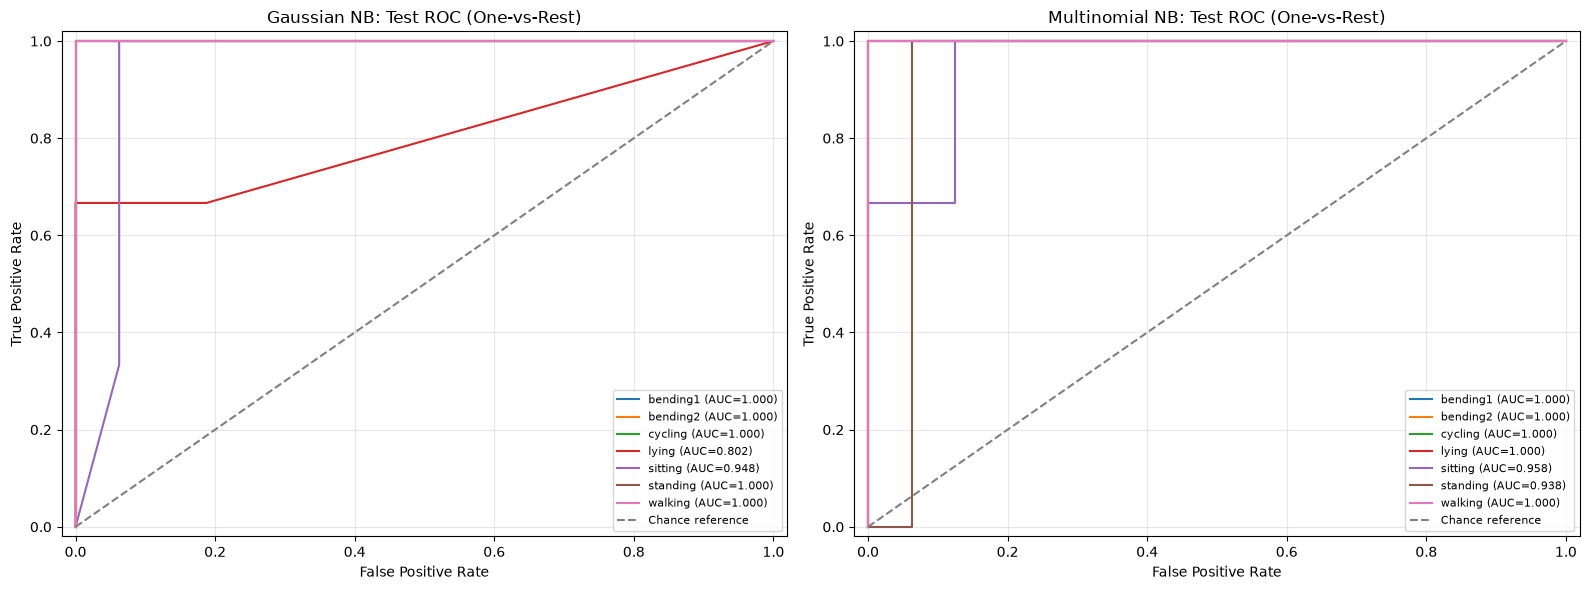

,Model,Activity,OvR AUC
0,Gaussian NB,bending1,1.000000
1,Gaussian NB,bending2,1.000000
2,Gaussian NB,cycling,1.000000
3,Gaussian NB,lying,0.802083
4,Gaussian NB,sitting,0.947917
5,Gaussian NB,standing,1.000000
6,Gaussian NB,walking,1.000000
7,Multinomial NB,bending1,1.000000
8,Multinomial NB,bending2,1.000000
9,Multinomial NB,cycling,1.000000


In [69]:
nb_auc_rows = []

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for ax, (model_name, fitted_model) in zip(
    axes,
    nb_fitted_models.items()
):
    classes = fitted_model.classes_
    probabilities = nb_test_probabilities[model_name]

    test_indicator = label_binarize(
        y_test_multiclass,
        classes=classes
    )

    for class_index, activity in enumerate(classes):
        binary_labels = test_indicator[:, class_index]
        activity_probability = probabilities[:, class_index]

        fpr, tpr, _ = roc_curve(
            binary_labels,
            activity_probability
        )

        activity_auc = roc_auc_score(
            binary_labels,
            activity_probability
        )

        nb_auc_rows.append({
            "Model": model_name,
            "Activity": activity,
            "OvR AUC": activity_auc
        })

        ax.plot(
            fpr,
            tpr,
            label=f"{activity} (AUC={activity_auc:.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray",
        label="Chance reference"
    )

    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title=f"{model_name}: Test ROC (One-vs-Rest)",
        xlim=(-0.02, 1.02),
        ylim=(-0.02, 1.02)
    )

    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

nb_auc_table = pd.DataFrame(nb_auc_rows)

display(nb_auc_table)

In [70]:
nb_macro_auc_table = (
    nb_auc_table
    .groupby("Model", as_index=False)["OvR AUC"]
    .mean()
    .rename(columns={
        "OvR AUC": "Macro OvR AUC"
    })
)

nb_full_evaluation = nb_evaluation_table.merge(
    nb_macro_auc_table,
    on="Model",
    how="left"
)

display(nb_full_evaluation)

,Model,Best l,Features,CV Accuracy,Training Accuracy,Test Accuracy,Test Error,Macro OvR AUC
0,Gaussian NB,1,42,0.857143,1.000000,0.894737,0.105263,0.964286
1,Multinomial NB,1,42,0.854945,0.927536,0.894737,0.105263,0.985119


Both Gaussian and Multinomial Naive Bayes select l = 1, using all 42 full-series features. Their CV accuracies are 85.71% and 85.49%, respectively. Both correctly classify 17 of 19 test instances, achieving 89.47% test accuracy and a test error of 10.53%.

#### iii. Comparison

In [71]:
l1_multiclass_row = pd.DataFrame([{
    "Model": "L1 Multinomial Logistic Regression",
    "Best l": best_multiclass_l,
    "Features": len(best_multiclass_used_features),
    "CV Accuracy": best_multiclass_cv_accuracy,
    "Training Accuracy": multiclass_train_accuracy,
    "Test Accuracy": multiclass_test_accuracy,
    "Test Error": multiclass_test_error,
    "Macro OvR AUC": multiclass_macro_auc
}])

multiclass_method_comparison = pd.concat(
    [
        l1_multiclass_row,
        nb_full_evaluation
    ],
    ignore_index=True
)

display(multiclass_method_comparison)

,Model,Best l,Features,CV Accuracy,Training Accuracy,Test Accuracy,Test Error,Macro OvR AUC
0,L1 Multinomial Logistic Regression,2,83,0.928571,1.000000,0.842105,0.157895,0.983894
1,Gaussian NB,1,42,0.857143,1.000000,0.894737,0.105263,0.964286
2,Multinomial NB,1,42,0.854945,0.927536,0.894737,0.105263,0.985119


Based on test classification accuracy, Gaussian and Multinomial Naive Bayes perform best on this split. Both achieve 89.47% test accuracy and a test error of 10.53%, compared with 84.21% accuracy and 15.79% error for L1 multinomial logistic regression.

Multinomial NB also achieves the highest macro-average OvR AUC of 0.9851, followed closely by L1 multinomial logistic regression at 0.9839 and Gaussian NB at 0.9643. Thus, Multinomial NB has the most favorable combination of the reported test accuracy and ranking performance.

However, L1 multinomial logistic regression has the highest CV accuracy of 92.86%, compared with approximately 85.7% and 85.5% for the Naive Bayes models. The test set contains only 19 instances, and the accuracy advantage of Naive Bayes corresponds to one additional correct prediction. These results therefore describe performance on this particular split rather than establishing general superiority.

## 3. ISLR 4.8.3

Let $\pi_k=P(Y=k)$ and let $f_k(x)$ be the density of $N(\mu_k,\sigma_k^2)$. By Bayes’ theorem,

$$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}
$$.

Since the denominator is common to all classes, the Bayes classifier maximizes $\pi_k f_k(x)$. Taking logarithms and discarding the class-independent term $-\frac12\log(2\pi)$, we obtain

$$
\delta_k(x)
=
\log\pi_k-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
+\log\pi_k-\frac12\log\sigma_k^2
-\frac{\mu_k^2}{2\sigma_k^2}.
$$

Thus, each discriminant function is quadratic in $x$. The boundary between classes $k$ and $\ell$ satisfies $\delta_k(x)-\delta_\ell(x)=0$, whose quadratic coefficient is

$$
\frac{1}{2\sigma_\ell^2}-\frac{1}{2\sigma_k^2}.
$$

This coefficient is nonzero when the class variances differ, so the boundary equation is generally quadratic. If all class variances are equal, the quadratic terms cancel when comparing classes, recovering the linear discriminant rule as a special case.


## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ denote issuing a dividend. The given class priors are $P(Y=\text{Yes})=0.8$ and $P(Y=\text{No})=0.2$, with

$$
X\mid Y=\text{Yes}\sim N(10,36),
\qquad
X\mid Y=\text{No}\sim N(0,36).
$$

The standard deviation is $\sqrt{36}=6$. At $X=4$, the class-conditional densities are

$$
f_{\text{Yes}}(4)
=
\frac{1}{6\sqrt{2\pi}}e^{-1/2},
\qquad
f_{\text{No}}(4)
=
\frac{1}{6\sqrt{2\pi}}e^{-2/9}.
$$

Applying Bayes’ theorem and cancelling the common density factor gives

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx0.75185.
$$

Therefore, the estimated probability that the company will issue a dividend is approximately **75.19%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9